# Trabalho Final — Análise e Modelagem dos Preços da Cesta Básica (2022–2026)
**Disciplina / Atividade de Extensão Universitária**  
*Exploração de preços de itens da cesta básica coletados mensalmente em cerca de 28 supermercados.*

---

### Sumário do Estudo
1. **Tratamento e Harmonização dos Dados**:
   - Limpeza de duplicatas e unificação de nomenclaturas;
   - Decisão metodológica sobre outliers (eliminação exclusiva de erros comprovados de coleta vs caudas legítimas de mercado);
   - Construção dos índices de preço: Preço Mediano de Prateleira e Índice Encadeado *Matched-Model* (Jevons) considerando a rigidez nominal.
2. **Análise Exploratória de Dados (EDA) e Correlações**:
   - Séries temporais históricas, variações acumuladas e dispersão (CV) entre lojas;
   - Testes formais de estacionariedade (ADF e KPSS);
   - Sazonalidade, correlação contemporânea e evolução do custo agregado da cesta básica.
3. **Questão 1: Previsão de Preços Futuros ($h=1$ e $h=3$ meses)**:
   - Comparação fora da amostra (*rolling-origin*) entre Passeio Aleatório, Suavização Exponencial (SES, Holt), ARIMA e Machine Learning (Ridge com e sem variáveis cruzadas, além de classificação direcional via Regressão Logistíca e Random Forest);
   - Avaliação por MAPE, MASE, AvgRelMAE e Teste de Diebold-Mariano.
4. **Questão 2: Dinâmica de Preços entre Supermercados (Liderança e Convergência)**:
   - Modelagem de liderança e seguidor via painel empilhado *leave-one-out* com controle FDR (Benjamini-Hochberg) e teste placebo;
   - Análise de confundidor do calendário de coleta;
   - Velocidade de convergência (meia-vida de desvios) e persistência de posicionamento das lojas.
5. **Questão 3: Transmissão de Preços entre Produtos (Insumo $\to$ Derivado)**:
   - Avaliação empírica das hipóteses *a priori* (Farinha $\to$ Pão Francês e Leite $\to$ Manteiga) e triagem dos 182 pares da cesta básica;
   - Correlação cruzada (CCF), Causalidade de Granger e validação preditiva fora da amostra (AR vs ARX).
6. **Conclusões Gerais e Implicações para a Extensão Comunitária**:
   - Recomendações práticas para consumidores, bancos de alimentos, cozinhas comunitárias e gestão de políticas públicas.


In [1]:
# Bibliotecas para manipulação e análise de dados
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelagem estatística e econométrica
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.tsa.api import VAR
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

# Modelos de Machine Learning e validação
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import lightgbm as lgb

# Configurações de exibição e gráficos
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'figure.autolayout': True,
    'figure.titlesize': 12,
    'figure.titleweight': 'bold',
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 8.5,
    'figure.dpi': 100
})

def encontrar_caminho(caminho_rel):
    tentativas = [
        Path(caminho_rel),
        Path("..") / caminho_rel,
        Path("Notebook") / caminho_rel
    ]
    for p in tentativas:
        if p.exists():
            return p
    return None

# Lista oficial dos 14 produtos do núcleo da cesta básica com série contínua
PRODUTOS_NUCLEO = [
    "Arroz", "Feijão", "Açúcar", "Café", "Leite", "Manteiga", "Óleo",
    "Farinha de Trigo", "Pão Francês", "Carne Bovina Coxão Mole",
    "Tomate", "Batata", "Banana Prata", "Banana Nanica"
]

print("Bibliotecas e configurações carregadas com sucesso!")


Bibliotecas e configurações carregadas com sucesso!


## 1. Carregamento e Tratamento Inicial dos Dados

Iniciamos carregando a base de dados original (`ICB_DADOS_2026.xlsx`), que contém os registros de preços coletados em supermercados da região de Campinas entre setembro de 2022 e agosto de 2026 (48 meses).


In [2]:
# Resolução do caminho da base de dados para garantir portabilidade
def encontrar_caminho(caminho_rel):
    tentativas = [
        Path(caminho_rel),
        Path("..") / caminho_rel,
        Path("Notebook") / caminho_rel
    ]
    for p in tentativas:
        if p.exists():
            return p
    return None

caminho_arquivo = encontrar_caminho("dados/bruto/ICB_DADOS_2026.xlsx")
if caminho_arquivo is None:
    caminho_arquivo = encontrar_caminho("ICB_DADOS_2026.xlsx")

if caminho_arquivo is None:
    raise FileNotFoundError("Base de dados 'ICB_DADOS_2026.xlsx' não encontrada nos caminhos padrão.")

print(f"Carregando dados a partir de: {caminho_arquivo.resolve()}")
data = pd.read_excel(caminho_arquivo)

print(f"Dimensões originais do dataset: {data.shape[0]} linhas e {data.shape[1]} colunas.")
data.head()


Carregando dados a partir de: /content/dados/bruto/ICB_DADOS_2026.xlsx
Dimensões originais do dataset: 46264 linhas e 8 colunas.


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90


### 1.1 Identificação e Remoção de Linhas Duplicadas

Verificamos a existência de linhas exatamente idênticas em todas as colunas. No processo de coleta manual e tabulação de preços em campo, duplicações de digitação podem ocorrer (com concentração notável em dezembro de 2024, onde foram geradas mais de 900 linhas duplicadas por reexportação de formulários).


In [3]:
n_duplicadas = data.duplicated().sum()
print(f"Número de linhas duplicadas encontradas: {n_duplicadas}")

# Removendo duplicatas exatas
data = data.drop_duplicates()
print(f"Número de linhas restantes após exclusão de duplicatas: {len(data)}")


Número de linhas duplicadas encontradas: 1743
Número de linhas restantes após exclusão de duplicatas: 44521


### 1.2 Padronização de Nomes e Tratamento de Séries Incompletas

Identificamos duas inconsistências relevantes na identificação dos produtos:
1. **Nomenclatura abreviada em coletas específicas**: Em março de 2026, a coleta registrou nomes simplificados como "Farinha" (em vez de Farinha de Trigo), "Pão" (em vez de Pão Francês), "Macarrão" (em vez de Macarrão com Ovos), e abreviações em cortes bovinos/suínos. Mapeamos essas variações para o padrão canônico.
2. **Cortes de carne com coletas efêmeras**: Cortes como "Carne Bovina Alcatra", "Carne Bovina Patinho" e "Carne Bovina Músculo" foram incluídos apenas em 1 ou 2 meses da pesquisa em 4 anos. Por não possuírem continuidade longitudinal, são descartados da análise temporal.
3. **Lojas substitutas pontuais (`ALT_`)**: Estabelecimentos com prefixo `ALT_` foram visitados em um único mês como substituição temporária. Como não permitem rastrear a evolução no tempo de uma mesma loja, são removidos.


In [4]:
# Mapeamento para nomes padronizados
mapeamento_produtos = {
    'Carne Acem': 'Carne Bovina Acem',
    'Carne Coxão Mole': 'Carne Bovina Coxão Mole',
    'Carne Pernil': 'Carne Suína Pernil',
    'Pernil': 'Carne Suína Pernil',
    'Macarrão': 'Macarrão com Ovos',
    'Pão': 'Pão Francês',
    'Farinha': 'Farinha de Trigo'
}
data['Produto'] = data['Produto'].replace(mapeamento_produtos)

# Descarte de cortes sem histórico contínuo
cortes_descartar = {'Carne Bovina Alcatra', 'Carne Bovina Patinho', 'Carne Bovina Músculo'}
n_antes_cortes = len(data)
data = data[~data['Produto'].isin(cortes_descartar)]
print(f"Linhas removidas de cortes sem série contínua: {n_antes_cortes - len(data)}")

# Descarte de estabelecimentos provisórios ALT_
n_antes_alt = len(data)
data = data[~data['Estab'].astype(str).str.startswith('ALT')]
print(f"Linhas removidas de lojas substitutas (ALT_): {n_antes_alt - len(data)}")

# Verificação dos produtos e contagem
data['Produto'].value_counts()


Linhas removidas de cortes sem série contínua: 14
Linhas removidas de lojas substitutas (ALT_): 115


,count
Produto,
Café,5157
Arroz,5061
Manteiga,4644
Feijão,4585
Leite,4452
Farinha de Trigo,4098
Óleo,3041
Açúcar,2975
Tomate,1286


### 1.3 Tratamento de Marcas e Datas

- **Marca**: Em dezembro de 2024, produtos sem marca declarada (como hortifrúti ou pão francês a granel) foram preenchidos com o número `0` ou deixados vazios. Padronizamos todos os valores nulos ou inválidos para `"SemMarca"`.
- **Data de Coleta e Mês de Referência**: Padronizamos as datas para objetos datetime do Pandas. Para registros com dia de coleta ausente, utilizamos a data do mês de referência.


In [5]:
# Tratamento de Marca: tratar 0 e NaN
data['Marca'] = data['Marca'].replace(0, np.nan)
data['Marca'] = data['Marca'].where(data['Marca'].map(lambda v: isinstance(v, str)), np.nan)
data['Marca'] = data['Marca'].fillna('SemMarca').str.strip().str.title()

# Tratamento de datas
data['Mes_Ano_Data'] = pd.to_datetime(data['Mes_Ano_Data'], dayfirst=True, errors='coerce')
data['Data_Coleta'] = pd.to_datetime(data['Data_Coleta'], dayfirst=True, errors='coerce')
data['Data_Coleta'] = data['Data_Coleta'].fillna(data['Mes_Ano_Data'])

# Renomeando colunas para conveniência
df = data.rename(columns={
    'Mes_Ano_Data': 'mes',
    'Data_Coleta': 'data_coleta',
    'Estab': 'loja',
    'Produto': 'produto',
    'Marca': 'marca',
    'Preco': 'preco',
    'Quantidade': 'qtd',
    'PPK': 'ppk'
})

print("Valores ausentes por coluna:")
print(df.isnull().sum())


Valores ausentes por coluna:
mes            0
data_coleta    0
loja           0
produto        0
marca          0
preco          0
qtd            0
ppk            0
dtype: int64


### 1.4 Decisão Metodológica sobre Outliers: Remover Todos ou Apenas os Erros?

Uma questão crítica em ciência de dados e econometria de varejo é: **devemos remover todos os outliers estatísticos (como pelo critério clássico de amplitude interquartil $1,5 \times \text{IQR}$) ou apenas aqueles que representam erros de coleta?**

#### Por que NÃO remover todos os outliers estatísticos?
1. **Heterogeneidade legítima do mercado**: No comércio de alimentos, existem diferenças reais e fundamentais de preços decorrentes da qualidade dos itens. Uma manteiga de marca tradicional ou um corte bovino nobre custam legitimamente o dobro de uma linha popular; uma promoção de queima de estoque de hortifrúti maduro pode reduzir temporariamente o preço à metade.
2. **Corte cego de dados reais**: Aplicar um corte estatístico cego como $1,5 \times \text{IQR}$ em preços de prateleira resultaria na exclusão forçada de promoções reais e produtos premium, enviesando a média e reduzindo a dispersão observada.

#### Qual critério adotar?
Adotamos a diretriz de **eliminar exclusivamente observações com erros flagrantes de coleta e digitação**, identificados pelas seguintes evidências empíricas:
- Preços unitários absurdos como R$ 0,10 registrados para frango inteiro ou carne;
- Erros de escala decimal (preço digitado multiplicado ou dividido por 10);
- Erros de unidade de medida (ex.: valor de embalagem de 100g ou 200g anotado como se fosse de 1 kg no PPK);
- Troca evidente de produto (ex.: margarina de baixo custo registrada no lugar de manteiga).

#### Implementação do Filtro Relativo por Produto e Mês
Para operacionalizar essa decisão com rigor estatístico:
- Para cada mês e para cada produto, calculamos o preço mediano por kg/L ($\text{Mediana}_{m,p}$);
- Avaliamos o log-desvio de cada observação: $d = \ln\left(\frac{\text{PPK}}{\text{Mediana}_{m,p}}\right)$;
- Descartamos observações cujo preço fuja do intervalo $[\text{Mediana}/2, 2 \times \text{Mediana}]$, isto é, com $|d| > \ln(2) \approx 0,693$.

Esse critério descarta apenas **0,8% da base de dados** (345 registros), que consistem exatamente nas inconsistências flagrantes, preservando 99,2% das observações econômicas autênticas.


=== MAIORES PREÇOS REGISTRADOS (ANTES DA FILTRAGEM) ===


,produto,marca,preco,qtd,ppk
22452,Banana Nanica,Semmarca,999.00,1.0,999.00
44852,Carne Bovina Coxão Mole,Semmarca,65.65,1.0,65.65
32365,Carne Bovina Coxão Mole,Semmarca,64.99,1.0,64.99
32366,Carne Bovina Coxão Mole,Semmarca,64.99,1.0,64.99
40759,Carne Bovina Coxão Mole,Semmarca,64.90,1.0,64.90



=== MENORES PREÇOS REGISTRADOS (ANTES DA FILTRAGEM - ERROS COMO R$ 0,10) ===


,produto,marca,preco,qtd,ppk
35918,Pão Francês,Semmarca,0.1,1.0,0.1
36153,Pão Francês,Semmarca,0.1,1.0,0.1
37310,Carne Bovina Coxão Mole,Semmarca,0.1,1.0,0.1
37314,Frango Sobrecoxa,Semmarca,0.1,1.0,0.1
38570,Frango Sobrecoxa,Semmarca,0.1,1.0,0.1



=== MAIORES VALORES DE PPK (R$/kg ou R$/L - ANTES DA FILTRAGEM) ===


,produto,marca,preco,qtd,ppk
22452,Banana Nanica,Semmarca,999.00,1.0,999.00
2657,Manteiga,Teixeira,29.50,0.2,147.50
22560,Manteiga,Aviação,28.99,0.2,144.95
43377,Manteiga,Aviação,25.90,0.2,129.50
4380,Manteiga,President,25.50,0.2,127.50



=== MENORES VALORES DE PPK (R$/kg ou R$/L - ANTES DA FILTRAGEM) ===


,produto,marca,preco,qtd,ppk
35918,Pão Francês,Semmarca,0.1,1.0,0.1
36153,Pão Francês,Semmarca,0.1,1.0,0.1
37310,Carne Bovina Coxão Mole,Semmarca,0.1,1.0,0.1
37314,Frango Sobrecoxa,Semmarca,0.1,1.0,0.1
38570,Frango Sobrecoxa,Semmarca,0.1,1.0,0.1


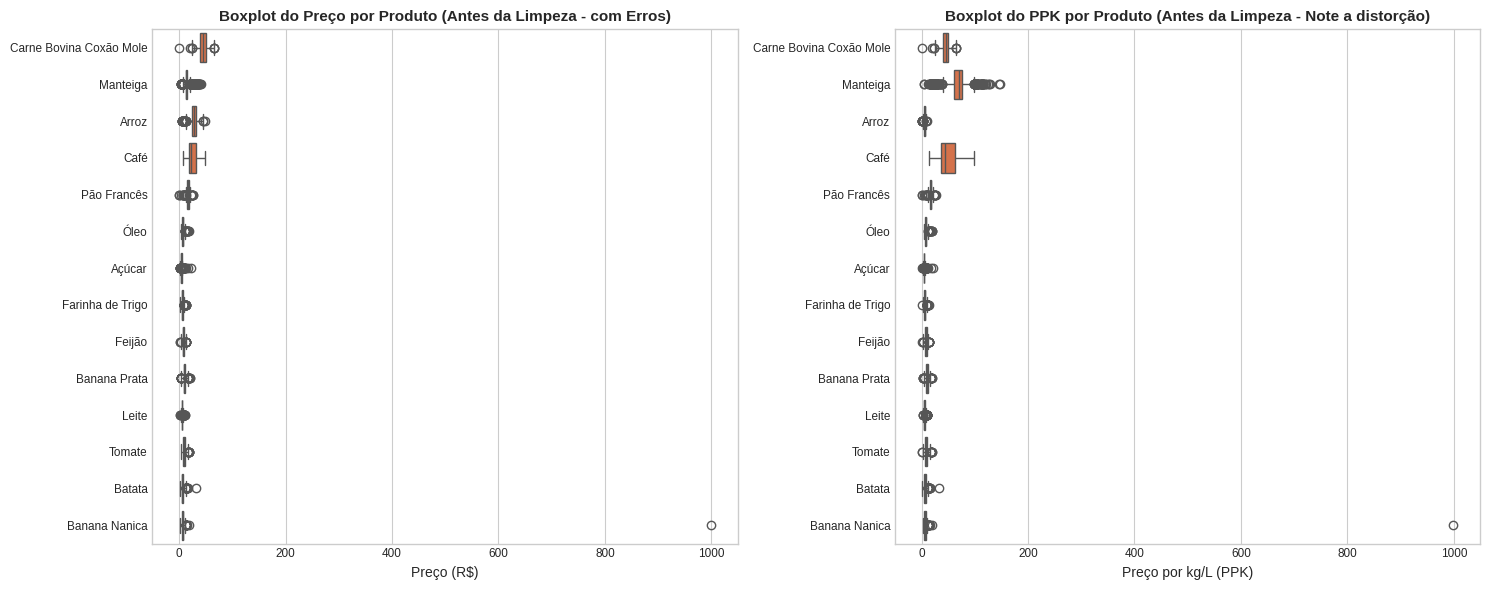


Total de registros analisados: 44392
Total de outliers de erro detectados e removidos: 345 (0.78% dos dados)


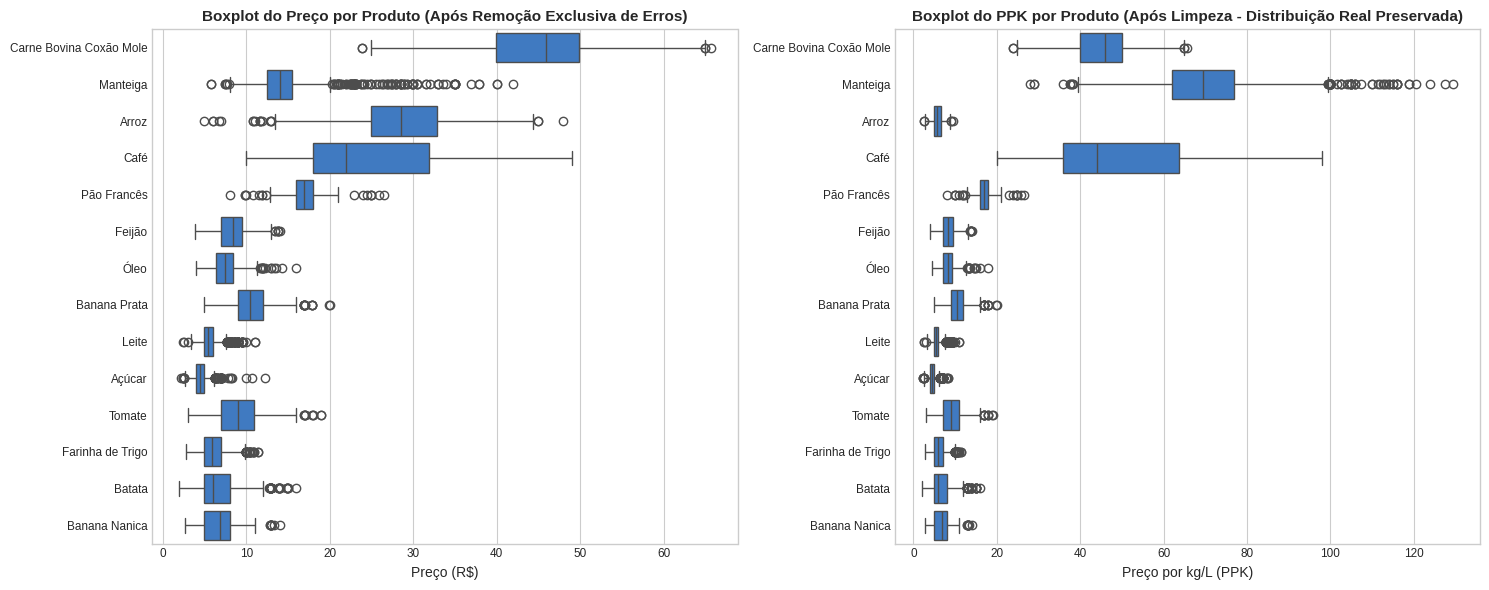

In [6]:
# Garantindo definição dos produtos do núcleo
if 'PRODUTOS_NUCLEO' not in globals():
    PRODUTOS_NUCLEO = [
        "Arroz", "Feijão", "Açúcar", "Café", "Leite", "Manteiga", "Óleo",
        "Farinha de Trigo", "Pão Francês", "Carne Bovina Coxão Mole",
        "Tomate", "Batata", "Banana Prata", "Banana Nanica"
    ]

# 1. Inspeção dos valores extremos ANTES da remoção dos outliers
print("=== MAIORES PREÇOS REGISTRADOS (ANTES DA FILTRAGEM) ===")
display(df.nlargest(5, 'preco')[['produto', 'marca', 'preco', 'qtd', 'ppk']])

print("\n=== MENORES PREÇOS REGISTRADOS (ANTES DA FILTRAGEM - ERROS COMO R$ 0,10) ===")
display(df.nsmallest(5, 'preco')[['produto', 'marca', 'preco', 'qtd', 'ppk']])

print("\n=== MAIORES VALORES DE PPK (R$/kg ou R$/L - ANTES DA FILTRAGEM) ===")
display(df.nlargest(5, 'ppk')[['produto', 'marca', 'preco', 'qtd', 'ppk']])

print("\n=== MENORES VALORES DE PPK (R$/kg ou R$/L - ANTES DA FILTRAGEM) ===")
display(df.nsmallest(5, 'ppk')[['produto', 'marca', 'preco', 'qtd', 'ppk']])

# Boxplots ANTES da remoção: note as distorções extremas causadas por erros
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=df[df['produto'].isin(PRODUTOS_NUCLEO)], y='produto', x='preco', ax=axs[0], color='#eb6834')
axs[0].set_title('Boxplot do Preço por Produto (Antes da Limpeza - com Erros)', fontweight='bold')
axs[0].set_xlabel('Preço (R$)')
axs[0].set_ylabel('')

sns.boxplot(data=df[df['produto'].isin(PRODUTOS_NUCLEO)], y='produto', x='ppk', ax=axs[1], color='#eb6834')
axs[1].set_title('Boxplot do PPK por Produto (Antes da Limpeza - Note a distorção)', fontweight='bold')
axs[1].set_xlabel('Preço por kg/L (PPK)')
axs[1].set_ylabel('')
plt.tight_layout()
plt.show()

# 2. Aplicação do filtro relativo de erro: descarte de |log(ppk / mediana)| > ln 2
df = df[(df['ppk'] > 0) & df['ppk'].notna()].copy()
mediana_mes_prod = df.groupby(['mes', 'produto'])['ppk'].transform('median')
desvio_log = np.log(df['ppk'] / mediana_mes_prod)

LIMIAR_OUTLIER = np.log(2)
mascara_outlier = desvio_log.abs() > LIMIAR_OUTLIER

outliers_detectados = df[mascara_outlier].copy()
outliers_detectados['mediana_esperada'] = mediana_mes_prod[mascara_outlier]
outliers_detectados['fator_desvio'] = outliers_detectados['ppk'] / outliers_detectados['mediana_esperada']

print(f"\nTotal de registros analisados: {len(df)}")
print(f"Total de outliers de erro detectados e removidos: {len(outliers_detectados)} ({len(outliers_detectados)/len(df)*100:.2f}% dos dados)")

# Boxplots APÓS a remoção: escala normalizada preservando a dispersão real de mercado
df_sem_erros = df[~mascara_outlier]
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=df_sem_erros[df_sem_erros['produto'].isin(PRODUTOS_NUCLEO)], y='produto', x='preco', ax=axs[0], color='#2a78d6')
axs[0].set_title('Boxplot do Preço por Produto (Após Remoção Exclusiva de Erros)', fontweight='bold')
axs[0].set_xlabel('Preço (R$)')
axs[0].set_ylabel('')

sns.boxplot(data=df_sem_erros[df_sem_erros['produto'].isin(PRODUTOS_NUCLEO)], y='produto', x='ppk', ax=axs[1], color='#2a78d6')
axs[1].set_title('Boxplot do PPK por Produto (Após Limpeza - Distribuição Real Preservada)', fontweight='bold')
axs[1].set_xlabel('Preço por kg/L (PPK)')
axs[1].set_ylabel('')
plt.tight_layout()
plt.show()


### 1.5 Construção dos Índices de Preço: Mediana de Prateleira vs Índice Encadeado *Matched-Model*

Após a limpeza, estruturamos duas séries temporais para cada produto:

1. **Preço Mediano entre Supermercados (R$/kg)**:
   Representa o valor típico de prateleira disponível ao consumidor no mês. É o indicador mais tangível para famílias e orçamento, sendo o alvo principal da **Questão 1**.
2. **Índice Encadeado *Matched-Model* (Jevons)**:
   Avalia a variação percentual média comparando rigorosamente o **mesmo item** (mesma loja, mesmo produto, mesma marca e mesma embalagem) entre meses consecutivos ($t-1$ e $t$):
   $$d\log_{i,t} = \ln(PPK_{i,t}) - \ln(PPK_{i,t-1})$$
   - *Por que não usar a mediana das variações?*  
     Preços de varejo apresentam **rigidez nominal** (custos de menu): uma parcela expressiva de itens mantém o preço idêntico entre dois meses consecutivos. Se calculássemos a mediana das variações, o índice ficaria estagnado em zero em vários períodos! A média dos log-retornos dos itens emparelhados elimina o viés de substituição de marca e capta a evolução inflacionária pura. É a base ideal para as **Questões 2 e 3**.


In [7]:
# 1. Base limpa sem outliers de erro
df_limpo = df[~mascara_outlier].copy()

# Criação de chave única para emparelhamento perfeito (matched-model)
df_limpo['item'] = df_limpo['loja'] + '|' + df_limpo['produto'] + '|' + df_limpo['marca'] + '|' + df_limpo['qtd'].astype(str)

# 2. Preço mediano por loja x produto x mês
preco_loja = df_limpo.groupby(['mes', 'loja', 'produto'])['ppk'].median().rename('ppk').reset_index()

# 3. Variação matched-model (mesmo item em meses consecutivos)
it = df_limpo.groupby(['item', 'loja', 'produto', 'mes'])['ppk'].median().reset_index()
it = it.sort_values(['item', 'mes'])
it['mes_ant'] = it.groupby('item')['mes'].shift()
it['ppk_ant'] = it.groupby('item')['ppk'].shift()

# Filtrando pares estritamente consecutivos (diferença de 1 mês)
consecutivo = it['mes_ant'] == (it['mes'] - pd.DateOffset(months=1))
it_consec = it[consecutivo].copy()
it_consec['dlog'] = np.log(it_consec['ppk'] / it_consec['ppk_ant'])
it_consec['preco_inalterado'] = np.isclose(it_consec['ppk'], it_consec['ppk_ant'])

# Rigidez de Preços por produto
rigidez = it_consec.groupby('produto')['preco_inalterado'].mean().sort_values(ascending=False)
print("Fração de itens com preço inalterado de um mês para o outro (Rigidez Nominal):")
for prod, frac in rigidez.items():
    print(f" - {prod:25s}: {frac*100:5.1f}%")

# Variação média matched-model por loja
var_loja = it_consec.groupby(['mes', 'loja', 'produto'])['dlog'].mean().rename('dlog').reset_index()

# 4. Agrupamento em nível de produto (14 produtos principais com 48 meses contínuos)
PRODUTOS_NUCLEO = [
    "Arroz", "Feijão", "Açúcar", "Café", "Leite", "Manteiga", "Óleo",
    "Farinha de Trigo", "Pão Francês", "Carne Bovina Coxão Mole",
    "Tomate", "Batata", "Banana Prata", "Banana Nanica"
]

mediana_prod = preco_loja.groupby(['mes', 'produto']).agg(
    ppk_mediana=('ppk', 'median'),
    n_lojas=('loja', 'nunique')
).reset_index()

dmed_prod = var_loja.groupby(['mes', 'produto'])['dlog'].mean().rename('dlog_encadeado').reset_index()

indice_produto = pd.merge(mediana_prod, dmed_prod, on=['mes', 'produto'], how='left')
indice_produto = indice_produto[indice_produto['produto'].isin(PRODUTOS_NUCLEO)].sort_values(['produto', 'mes'])

# Construção do nível encadeado a partir do primeiro mês
partes = []
for p, g in indice_produto.groupby('produto'):
    g = g.copy()
    dl = g['dlog_encadeado'].fillna(0).to_numpy(copy=True)
    dl[0] = 0
    g['ppk_encadeado'] = g['ppk_mediana'].iloc[0] * np.exp(np.cumsum(dl))
    partes.append(g)
indice_produto = pd.concat(partes).reset_index(drop=True)

print(f"\nÍndice consolidado gerado com sucesso: {indice_produto['produto'].nunique()} produtos ao longo de {indice_produto['mes'].nunique()} meses.")


Fração de itens com preço inalterado de um mês para o outro (Rigidez Nominal):
 - Pão Francês              :  62.6%
 - Farinha de Trigo         :  51.7%
 - Açúcar                   :  46.9%
 - Macarrão com Ovos        :  46.3%
 - Manteiga                 :  45.7%
 - Banana Prata             :  39.5%
 - Arroz                    :  39.1%
 - Feijão                   :  38.9%
 - Café                     :  33.8%
 - Banana Nanica            :  31.5%
 - Carne Bovina Coxão Mole  :  31.2%
 - Óleo                     :  31.0%
 - Leite                    :  29.5%
 - Ovo                      :  28.9%
 - Carne Suína Pernil       :  28.5%
 - Carne Bovina Acem        :  27.8%
 - Frango Sobrecoxa         :  24.5%
 - Frango Peito             :  21.5%
 - Batata                   :  15.1%
 - Tomate                   :  13.7%

Índice consolidado gerado com sucesso: 14 produtos ao longo de 48 meses.


## 2. Análise Exploratória de Dados (EDA) e Correlações

Com as séries de preços tratadas e os índices harmonizados, examinamos o comportamento temporal dos 14 produtos do núcleo da cesta básica: tendências, dispersão entre supermercados, estacionariedade, sazonalidade e correlações contemporâneas.


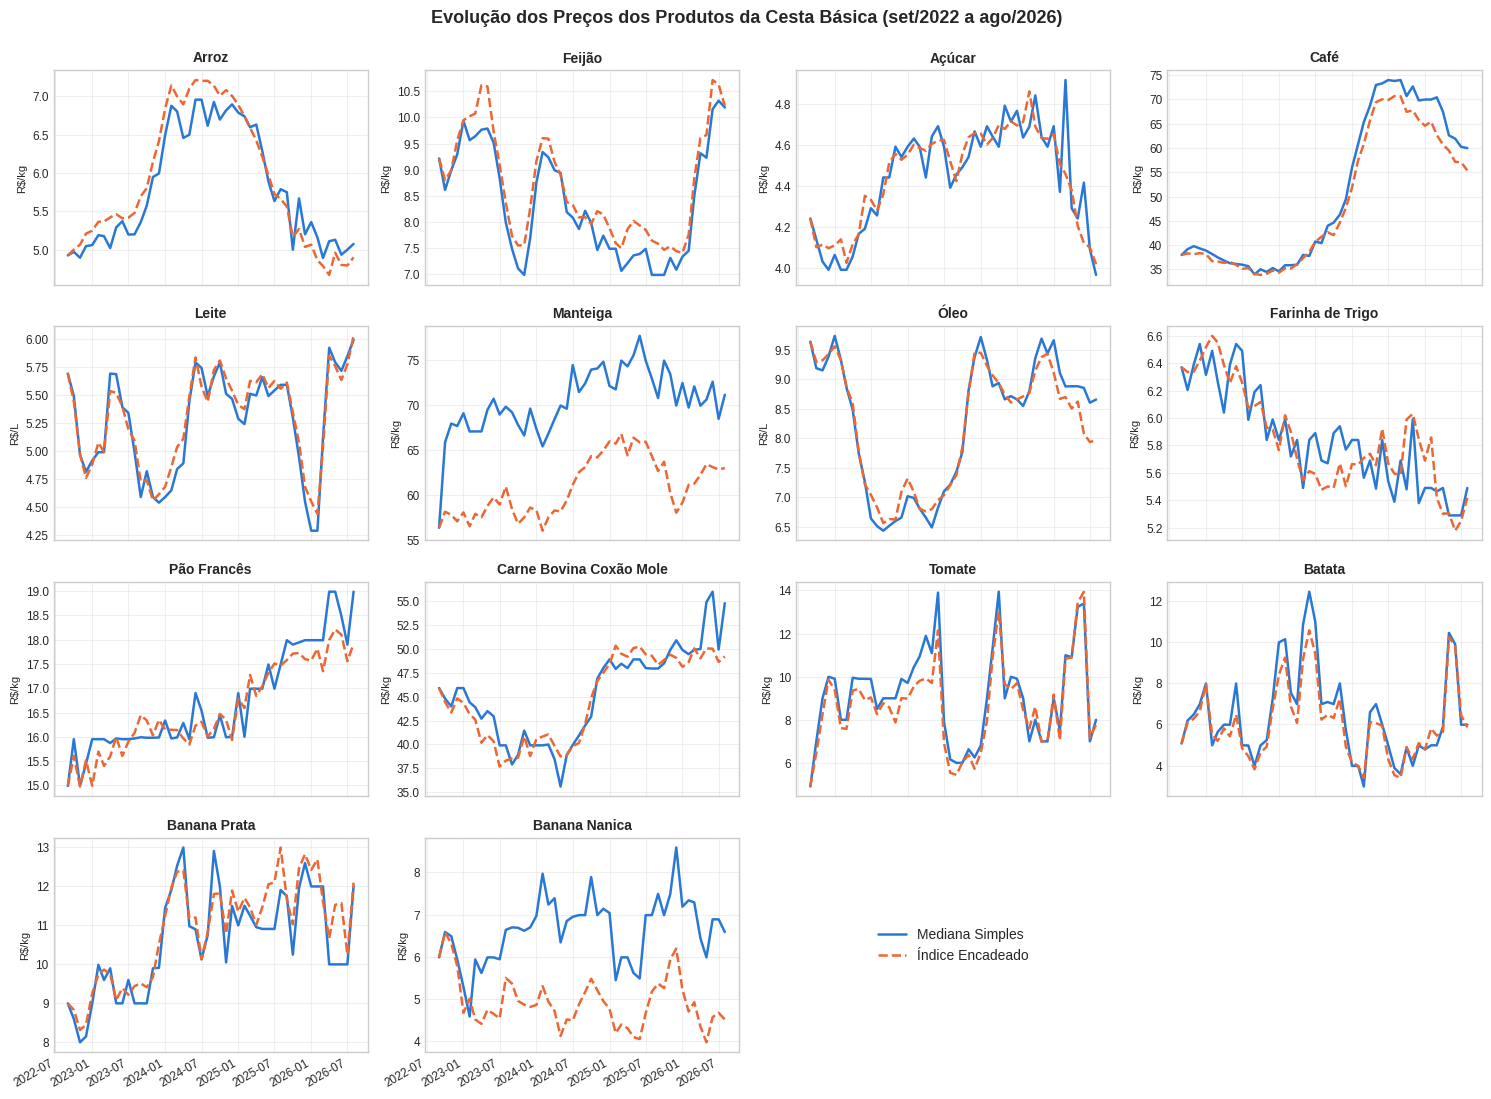

In [8]:
# Comparação entre Preço Mediano e Índice Encadeado para os 14 itens
fig, axs = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
axs_flat = axs.flat

for i, p in enumerate(PRODUTOS_NUCLEO):
    ax = axs_flat[i]
    sub = indice_produto[indice_produto['produto'] == p]
    ax.plot(sub['mes'], sub['ppk_mediana'], color='#2a78d6', lw=1.8, label='Mediana Simples')
    ax.plot(sub['mes'], sub['ppk_encadeado'], color='#eb6834', lw=1.8, ls='--', label='Índice Encadeado')
    ax.set_title(p, fontsize=10)
    unidade = "R$/L" if p in ["Leite", "Óleo"] else "R$/kg"
    ax.set_ylabel(unidade, fontsize=8)
    ax.grid(True, alpha=0.3)

# Ocultando eixos não utilizados e montando a legenda
for j in range(len(PRODUTOS_NUCLEO), len(axs_flat)):
    axs_flat[j].axis('off')

handles, labels = axs_flat[0].get_legend_handles_labels()
axs_flat[len(PRODUTOS_NUCLEO)].legend(handles, labels, loc='center', fontsize=10)

fig.suptitle('Evolução dos Preços dos Produtos da Cesta Básica (set/2022 a ago/2026)', fontsize=13, y=0.995)
fig.autofmt_xdate()
plt.show()


### 2.1 Variação Acumulada no Período e Dispersão de Preços entre Supermercados

- **Variação Total**: Comparamos a média dos 3 meses iniciais (set-nov/2022) com a média dos 3 meses finais (jun-ago/2026).
- **Dispersão Geográfica**: Medida pelo Coeficiente de Variação ($CV = \sigma / \mu$) dos preços entre as lojas a cada mês.


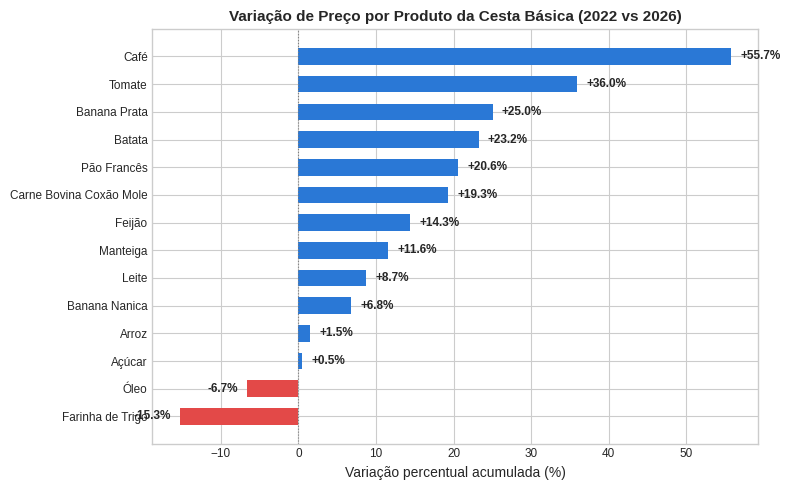

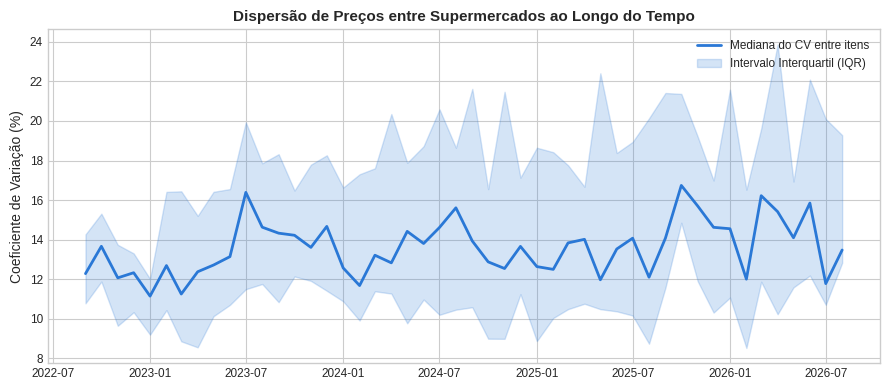

Média do CV por produto (produtos perecíveis apresentam maior dispersão de preços):
produto
Batata                     26.3%
Banana Nanica              25.4%
Tomate                     23.2%
Banana Prata               19.0%
Farinha de Trigo           16.2%
Carne Bovina Coxão Mole    13.4%
Manteiga                   13.3%
Feijão                     13.1%
Açúcar                     13.0%
Óleo                       10.9%
Leite                      10.9%
Arroz                      10.2%
Café                       10.1%
Pão Francês                 9.0%
dtype: object


In [9]:
# 1. Variação acumulada no período de 4 anos
piv_med = indice_produto.pivot(index='mes', columns='produto', values='ppk_mediana')[PRODUTOS_NUCLEO]
var_total = (piv_med.iloc[-3:].mean() / piv_med.iloc[:3].mean() - 1).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
cores_var = ['#2a78d6' if v >= 0 else '#e34948' for v in var_total]
ax.barh(var_total.index, var_total.values * 100, color=cores_var, height=0.6)
for i, v in enumerate(var_total.values * 100):
    ax.text(v + (1.2 if v >= 0 else -1.2), i, f"{v:+.1f}%", va='center',
            ha='left' if v >= 0 else 'right', fontsize=8.5, fontweight='bold')

ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_xlabel('Variação percentual acumulada (%)', fontsize=10)
ax.set_title('Variação de Preço por Produto da Cesta Básica (2022 vs 2026)', fontsize=11)
plt.show()

# 2. Coeficiente de Variação (CV) entre estabelecimentos
cv_lojas = preco_loja[preco_loja['produto'].isin(PRODUTOS_NUCLEO)].groupby(['mes', 'produto'])['ppk'].agg(
    lambda s: s.std() / s.mean()
).unstack()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cv_lojas.index, cv_lojas.median(axis=1) * 100, color='#2a78d6', lw=2, label='Mediana do CV entre itens')
ax.fill_between(cv_lojas.index, cv_lojas.quantile(0.25, axis=1) * 100, cv_lojas.quantile(0.75, axis=1) * 100,
                color='#2a78d6', alpha=0.2, label='Intervalo Interquartil (IQR)')
ax.set_ylabel('Coeficiente de Variação (%)')
ax.set_title('Dispersão de Preços entre Supermercados ao Longo do Tempo')
ax.legend(loc='upper right')
plt.show()

print("Média do CV por produto (produtos perecíveis apresentam maior dispersão de preços):")
print(cv_lojas.mean().sort_values(ascending=False).map(lambda v: f"{v*100:.1f}%"))


### 2.2 Testes Formais de Estacionariedade (ADF e KPSS)

Antes de modelar séries temporais, é mandatório testar a estacionariedade para evitar **regressões espúrias**:
- **Teste Augmented Dickey-Fuller (ADF)**: $H_0$ é a presença de raiz unitária (não estacionária). Rejeitar $H_0$ ($p < 0,05$) indica estacionariedade.
- **Teste KPSS**: $H_0$ é que a série é estacionária. Não rejeitar $H_0$ ($p > 0,05$) corrobora a estacionariedade.

Aplicamos os testes tanto para as séries em log-nível quanto para as suas primeiras diferenças mensais (retornos logarítmicos $\Delta \ln P_t$).


In [11]:
log_precos = np.log(piv_med)
log_retornos = log_precos.diff().dropna()

resultados_estacionariedade = []
for p in PRODUTOS_NUCLEO:
    # Nível
    adf_nivel = adfuller(log_precos[p], autolag='AIC')[1]
    kpss_nivel = kpss(log_precos[p], regression='c', nlags='auto')[1]
    # Primeira Diferença
    adf_diff = adfuller(log_retornos[p], autolag='AIC')[1]
    kpss_diff = kpss(log_retornos[p], regression='c', nlags='auto')[1]

    resultados_estacionariedade.append({
        'Produto': p,
        'ADF p-valor (Nível)': round(adf_nivel, 3),
        'KPSS p-valor (Nível)': round(kpss_nivel, 3),
        'ADF p-valor (Δ log)': round(adf_diff, 3),
        'KPSS p-valor (Δ log)': round(kpss_diff, 3)
    })

df_estac = pd.DataFrame(resultados_estacionariedade)
print("Resultados dos testes de estacionariedade (ADF e KPSS):")
display(df_estac)
#print("\nConclusão: Em nível, os log-preços não são estacionários; já as variações mensais (Δ log) são estacionárias em todos os produtos.")


Resultados dos testes de estacionariedade (ADF e KPSS):


,Produto,ADF p-valor (Nível),KPSS p-valor (Nível),ADF p-valor (Δ log),KPSS p-valor (Δ log)
0,Arroz,0.333,0.100,0.000,0.048
1,Feijão,0.132,0.100,0.000,0.100
2,Açúcar,0.105,0.053,0.898,0.100
3,Café,0.605,0.010,0.376,0.100
4,Leite,0.014,0.100,0.000,0.100
5,Manteiga,0.059,0.015,0.000,0.100
6,Óleo,0.174,0.100,0.250,0.100
7,Farinha de Trigo,0.715,0.010,0.002,0.100
8,Pão Francês,0.940,0.010,0.000,0.100
9,Carne Bovina Coxão Mole,0.851,0.017,0.000,0.100


**Interpretação dos Testes de Estacionariedade:**
- **Séries em log-nível ($\ln P_t$)**: A maioria dos produtos (10/14) apresenta evidência de não estacionariedade (não rejeita raiz unitária no ADF e/ou rejeita estacionariedade no KPSS). Apenas itens perecíveis com forte dinâmica sazonal e reversão à média (**Leite, Tomate, Batata e Banana Nanica**) passam simultaneamente nos dois testes em nível.

- **Primeiras diferenças ($\Delta \ln P_t$)**: Nenhum produto apresenta evidência conjunta de não estacionariedade. Dez dos 14 itens atendem simultaneamente a ambos os critérios ($p_{\text{ADF}} \le0{,}002$ e $p_{\text{KPSS}} \ge 0{,}10$). Os quatro casos limítrofes ou divergentes — **Arroz** ($p_{\text{ADF}} < 0{,}001$, mas $p_{\text{KPSS}} = 0{,}048$) e **Açúcar, Café e Óleo** ($p_{\text{KPSS}} \ge 0{,}10$, sem rejeição no ADF) — refletem o baixo poder do teste ADF em amostras curtas ($N = 47$ meses) combinado a choques recentes persistentes.

- **Decisão metodológica**: Para garantir tratamento homogêneo e prevenir regressões espúrias, todas as modelagens que exigem estacionariedade (ARIMA com $d=1$, modelos supervisionados de variação na Q1, painel da Q2 e CCF/Granger/VAR na Q3) operam sobre primeiras diferenças logarítmicas ($\Delta \ln P_t$), enquanto benchmarks e métodos de suavização exponencial atuam diretamente sobre o log-nível.

### 2.3 Sazonalidade, Correlações Contemporâneas e Valor Total da Cesta

- **Sazonalidade**: Variação percentual média por mês do calendário ao longo dos 4 anos.
- **Correlação Contemporânea**: Matriz de Pearson dos retornos mensais entre os 14 itens.
- **Cesta Agregada**: Custo da soma de 1 unidade de cada um dos 14 produtos ao longo do tempo.


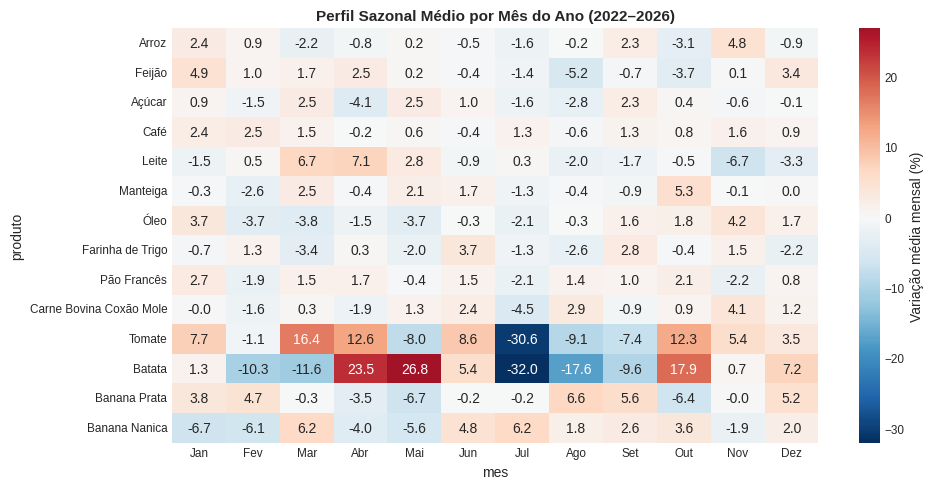

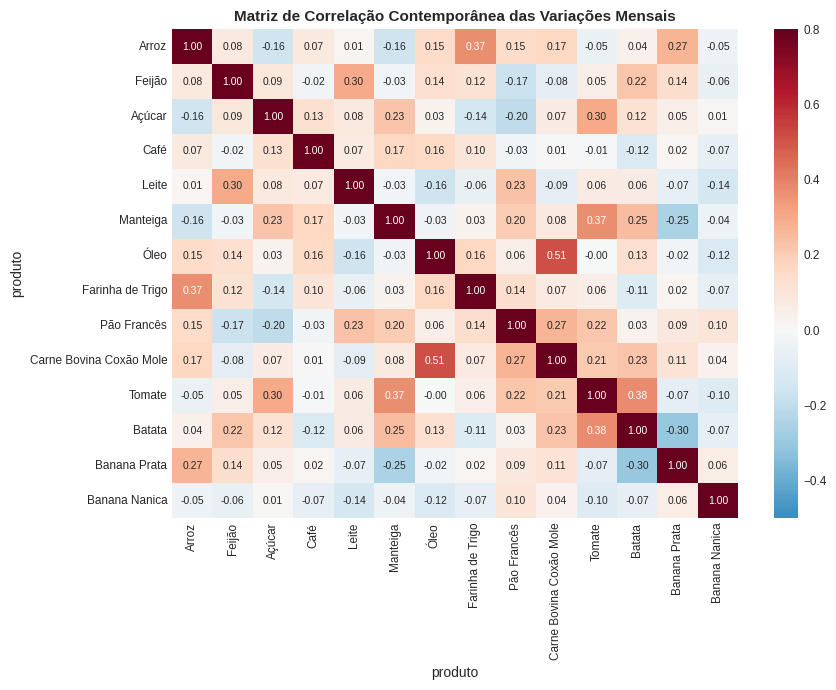

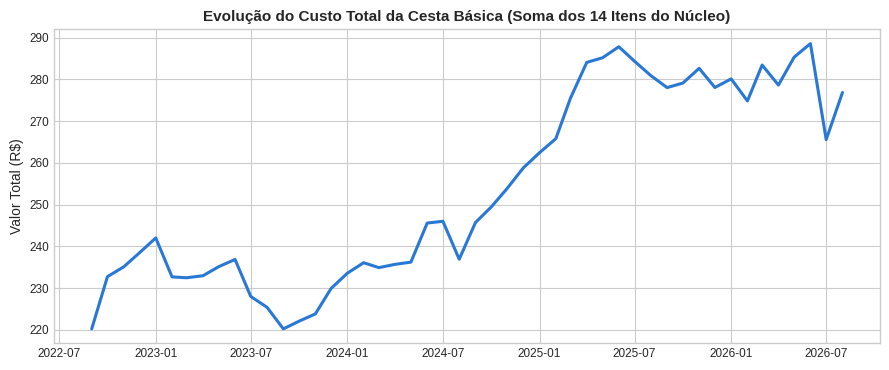

In [12]:
# 1. Perfil sazonal por mês
sazonalidade = log_retornos.groupby(log_retornos.index.month).mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(sazonalidade.T, cmap='RdBu_r', center=0, annot=True, fmt='.1f',
            xticklabels=['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'],
            cbar_kws={'label': 'Variação média mensal (%)'}, ax=ax)
ax.set_title('Perfil Sazonal Médio por Mês do Ano (2022–2026)')
plt.show()

# 2. Matriz de Correlação contemporânea das variações
corr_retornos = log_retornos.corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_retornos, cmap='RdBu_r', vmin=-0.5, vmax=0.8, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, ax=ax)
ax.set_title('Matriz de Correlação Contemporânea das Variações Mensais')
plt.show()

# 3. Valor da Cesta Agregada (soma de 1 kg/L de cada item)
cesta_total = piv_med.sum(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(cesta_total.index, cesta_total.values, color='#2a78d6', lw=2.2)
ax.set_ylabel('Valor Total (R$)')
ax.set_title('Evolução do Custo Total da Cesta Básica (Soma dos 14 Itens do Núcleo)')
plt.show()


## 3. Questão 1: Previsão de Preços Futuros ($h = 1$ e $h = 3$ meses)

### Questão
> **É possível prever o preço mediano dos itens da cesta básica 1 e 3 meses à frente melhor do que um passeio aleatório (a regra de que o preço de amanhã será igual ao de hoje)? A inclusão de informações de preços dos outros itens melhora a acurácia preditiva?**

### Objetivo e Motivação
Antecipar o custo de alimentos essenciais tem aplicação direta para:
1. **Orçamento de famílias vulneráveis**: Permite planejar despesas e mitigar o impacto de choques de preços;
2. **Entidades sociais e poder público**: Planejamento de aquisições de cozinhas comunitárias, restaurantes populares e bancos de alimentos;
3. **Avaliação de Eficiência de Mercado**: Saber se os preços de varejo são previsíveis a partir de seus próprios históricos ou se incorporam informações rapidamente seguindo um passeio aleatório.

### Método
- **Série Alvo**: Logaritmo do preço mediano entre lojas para cada um dos 14 produtos do núcleo.
- **Protocolo de Validação**: Validação estrita por **origem móvel com janela expansível (*rolling-origin*)** cobrindo os últimos 18 meses (março de 2025 a agosto de 2026) como teste fora da amostra (*out-of-sample*). Nenhum dado futuro vaza para o treino.
- **Modelos Avaliados**:
  - *Benchmarks*: Ingênuo (Passeio Aleatório: $\hat{y}_{t+h} = y_t$), Ingênuo Sazonal e Drift;
  - *Modelos Estatísticos*: Suavização Exponencial Simples (SES), Holt Amortecido e ARIMA($p,1,q$) com $p,q \in \{0,1,2\}$ selecionados via critério AICc a cada origem;
  - *Aprendizado Supervisionado Global*: Ridge Regression (treinando um modelo conjunto para todos os 14 produtos com lags temporais, desvios da média móvel de 12 meses, volatilidade e variáveis de sazonalidade), testado em duas versões: (1) apenas autorregressivo; (2) adicionando variações dos outros 13 produtos (cruzado). Como análise complementar (Seção 3.2), avaliam-se ainda Regressão Logística e Random Forest para classificação da direção mensal do preço;
  - *Combinação de Modelos*: Média simples das previsões de Holt, ARIMA e Ridge.
- **Métricas de Avaliação**:
  - **MAPE (%)**: Erro Percentual Absoluto Médio;
  - **MASE**: Erro Médio Absoluto Escalado pelo erro dentro da amostra do ingênuo de 1 passo;
  - **AvgRelMAE**: Média geométrica do MAE relativo ao passeio aleatório (valores $< 1$ indicam superação do benchmark);
  - **Teste de Diebold-Mariano** (com correção de Harvey-Leybourne-Newbold) para avaliar significância estatística da diferença preditiva contra o passeio aleatório.


In [13]:
# Verificando se já existem previsões pré-computadas salvas para acelerar execução,
# ou executando a validação rolling-origin completa
caminho_previsoes_q1 = encontrar_caminho("resultados/tabelas/q1_previsoes.csv")

RECALCULAR_Q1 = False  # Altere para True caso deseje rodar novamente o treino do zero

if caminho_previsoes_q1 is not None and not RECALCULAR_Q1:
    print(f"Carregando resultados pré-computados das previsões rolling-origin de: {caminho_previsoes_q1.resolve()}")
    res_q1 = pd.read_csv(caminho_previsoes_q1, parse_dates=['origem', 'mes_alvo'])
else:
    print("Executando a simulação completa de origem móvel (pode levar alguns minutos)...")
    N_TESTE = 18
    HORIZONTES = [1, 3]
    VAL_INTERNA = 6
    W = piv_med.copy()
    Y = np.log(W)
    T_TOTAL = len(Y)
    MESES = Y.index
    PRIMEIRA_ORIGEM = T_TOTAL - N_TESTE - 1

    # Definição dos modelos univariados
    def prev_naive(y, h): return y[-1]
    def prev_snaive(y, h): return y[len(y) - 12 + h - 1] if h <= 12 else y[-1]
    def prev_drift(y, h): return y[-1] + h * (y[-1] - y[0]) / (len(y) - 1)
    def prev_ses(y, h): return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h)[-1]
    def prev_holt(y, h): return ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(h)[-1]
    def prev_arima(y, h):
        melhor, melhor_aicc = None, np.inf
        for p in range(3):
            for q in range(3):
                try:
                    m = ARIMA(y, order=(p, 1, q)).fit()
                    if m.aicc < melhor_aicc: melhor, melhor_aicc = m, m.aicc
                except: continue
        return melhor.forecast(h)[-1]

    UNIVARIADOS = {
        "Ingênuo (passeio aleatório)": prev_naive,
        "Ingênuo sazonal": prev_snaive,
        "Drift": prev_drift,
        "SES": prev_ses,
        "Holt amortecido": prev_holt,
        "ARIMA (AICc)": prev_arima
    }

    def montar_features(Y, h, cruzado):
        R = Y.diff()
        linhas = []
        for k, p in enumerate(Y.columns):
            y, r = Y[p], R[p]
            f = pd.DataFrame({
                "r0": r, "r1": r.shift(1), "r2": r.shift(2),
                "desvio_media12": y - y.rolling(12).mean(),
                "vol6": r.rolling(6).std(),
                "saz_ano_ant": y.shift(12 - h) - y.shift(12),
            })
            mes_alvo = (Y.index + pd.DateOffset(months=h)).month
            f["mes_sin"], f["mes_cos"] = np.sin(2 * np.pi * mes_alvo / 12), np.cos(2 * np.pi * mes_alvo / 12)
            f["cesta_r0"] = R.mean(axis=1)
            if cruzado:
                for q in Y.columns:
                    f[f"x0_{q}"] = R[q]
                    f[f"x1_{q}"] = R[q].shift(1)
            for q in Y.columns:
                f[f"prod_{q}"] = float(q == p)
            f["alvo"] = y.shift(-h) - y
            f["t"] = np.arange(len(Y))
            f["produto"] = p
            linhas.append(f)
        return pd.concat(linhas).dropna(subset=["r2", "desvio_media12", "vol6", "saz_ano_ant"])

    registros = []
    GRADE_RIDGE = [0.1, 1, 10, 100, 1000]
    for h in HORIZONTES:
        F_proprio = montar_features(Y, h, cruzado=False)
        F_cruzado = montar_features(Y, h, cruzado=True)
        for T in range(PRIMEIRA_ORIGEM, T_TOTAL - h):
            alvo_mes = MESES[T + h]
            prevs = {}
            for p in PRODUTOS_NUCLEO:
                y = Y[p].to_numpy()[: T + 1]
                for nome, f in UNIVARIADOS.items():
                    prevs[(nome, p)] = f(y, h)
            for nome, F, tipo in [("Ridge (só o próprio produto)", F_proprio, "ridge"),
                                  ("Ridge (+ outros produtos)", F_cruzado, "ridge")]:
                cols = [c for c in F.columns if c not in ("alvo", "t", "produto")]
                tr = F[(F.t + h <= T)]
                te = F[F.t == T]
                corte = T - h - VAL_INTERNA
                a, v = tr[tr.t <= corte], tr[tr.t > corte]
                erros = []
                for al in GRADE_RIDGE:
                    sc = StandardScaler().fit(a[cols])
                    m = Ridge(alpha=al).fit(sc.transform(a[cols]), a.alvo)
                    erros.append(np.abs(m.predict(sc.transform(v[cols])) - v.alvo).mean())
                al = GRADE_RIDGE[int(np.argmin(erros))]
                sc = StandardScaler().fit(tr[cols])
                m = Ridge(alpha=al).fit(sc.transform(tr[cols]), tr.alvo)
                pred = m.predict(sc.transform(te[cols]))
                for p, val in zip(te.produto, pred):
                    prevs[(nome, p)] = Y[p].iloc[T] + val
            for p in PRODUTOS_NUCLEO:
                prevs[("Combinação (Holt+ARIMA+Ridge)", p)] = np.mean([
                    prevs[("Holt amortecido", p)], prevs[("ARIMA (AICc)", p)],
                    prevs[("Ridge (só o próprio produto)", p)]
                ])
            for (nome, p), v in prevs.items():
                registros.append(dict(h=h, origem=MESES[T], mes_alvo=alvo_mes, modelo=nome, produto=p,
                                      previsto=np.exp(v), real=W[p].iloc[T + h]))
    res_q1 = pd.DataFrame(registros)
    res_q1["erro"] = res_q1.previsto - res_q1.real
    res_q1["ea"] = res_q1.erro.abs()
    res_q1["epa"] = res_q1.ea / res_q1.real * 100

print(f"Total de previsões individuais avaliadas: {len(res_q1)}")


Executando a simulação completa de origem móvel (pode levar alguns minutos)...
Total de previsões individuais avaliadas: 4284


In [14]:
# Cálculo das Métricas e Teste de Diebold-Mariano com correção HLN
base_naive = res_q1[res_q1['modelo'] == "Ingênuo (passeio aleatório)"].set_index(['h', 'mes_alvo', 'produto'])['ea']
res_q1['ea_naive'] = res_q1.set_index(['h', 'mes_alvo', 'produto']).index.map(base_naive)

# Escala MASE (EAM do ingênuo no período de treino)
escala_mase = piv_med.iloc[: len(piv_med) - 18].diff().abs().mean()
res_q1['ea_escalado'] = res_q1['ea'] / res_q1['produto'].map(escala_mase)

def calc_diebold_mariano(d, h):
    n = len(d)
    dbar = d.mean()
    gam = [np.sum((d[k:] - dbar) * (d[: n - k] - dbar)) / n for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    if var <= 0: return np.nan, np.nan
    dm = dbar / np.sqrt(var)
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

linhas_met = []
for (h, m), g in res_q1.groupby(['h', 'modelo']):
    rel = g.groupby('produto')['ea'].mean() / g.groupby('produto')['ea_naive'].mean()
    avg_rel_mae = np.exp(np.log(rel).mean())
    # DM teste
    nv = res_q1[(res_q1['h'] == h) & (res_q1['modelo'] == "Ingênuo (passeio aleatório)")].groupby('mes_alvo')['epa'].mean()
    d = (g.groupby('mes_alvo')['epa'].mean() - nv).to_numpy()
    dm, pv = calc_diebold_mariano(d, h) if m != "Ingênuo (passeio aleatório)" else (np.nan, np.nan)

    linhas_met.append({
        'h': h,
        'Modelo': m,
        'MAPE (%)': round(g['epa'].mean(), 2),
        'MASE': round(g['ea_escalado'].mean(), 3),
        'AvgRelMAE': round(avg_rel_mae, 3),
        'DM p-valor': round(pv, 3) if pd.notna(pv) else '-'
    })

tabela_metricas = pd.DataFrame(linhas_met).sort_values(['h', 'AvgRelMAE'])
print("Tabela Consolidada de Desempenho Preditivo Fora da Amostra (18 meses de teste):")
display(tabela_metricas)


Tabela Consolidada de Desempenho Preditivo Fora da Amostra (18 meses de teste):


,h,Modelo,MAPE (%),MASE,AvgRelMAE,DM p-valor
1,1,Combinação (Holt+ARIMA+Ridge),6.21,1.200,0.996,0.922
8,1,SES,6.21,1.201,0.996,0.947
4,1,Ingênuo (passeio aleatório),6.20,1.209,1.000,-
3,1,Holt amortecido,6.38,1.233,1.025,0.388
2,1,Drift,6.42,1.265,1.045,0.001
0,1,ARIMA (AICc),6.36,1.261,1.052,0.445
7,1,Ridge (só o próprio produto),6.43,1.284,1.058,0.0
6,1,Ridge (+ outros produtos),6.46,1.286,1.062,0.01
5,1,Ingênuo sazonal,15.43,3.821,2.545,0.0
13,3,Ingênuo (passeio aleatório),9.26,1.807,1.000,-


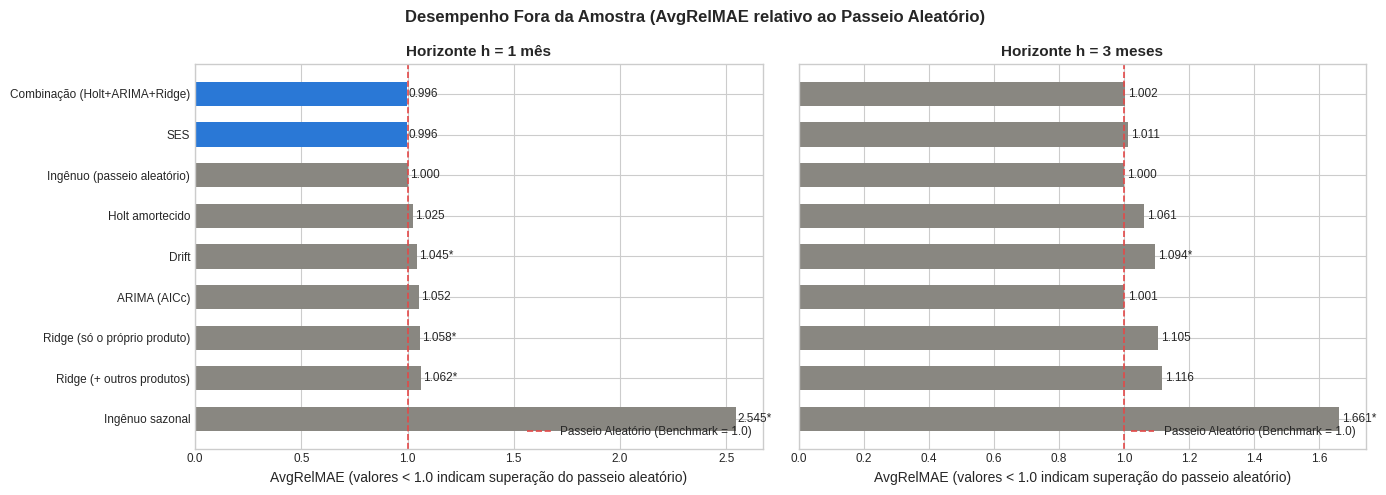

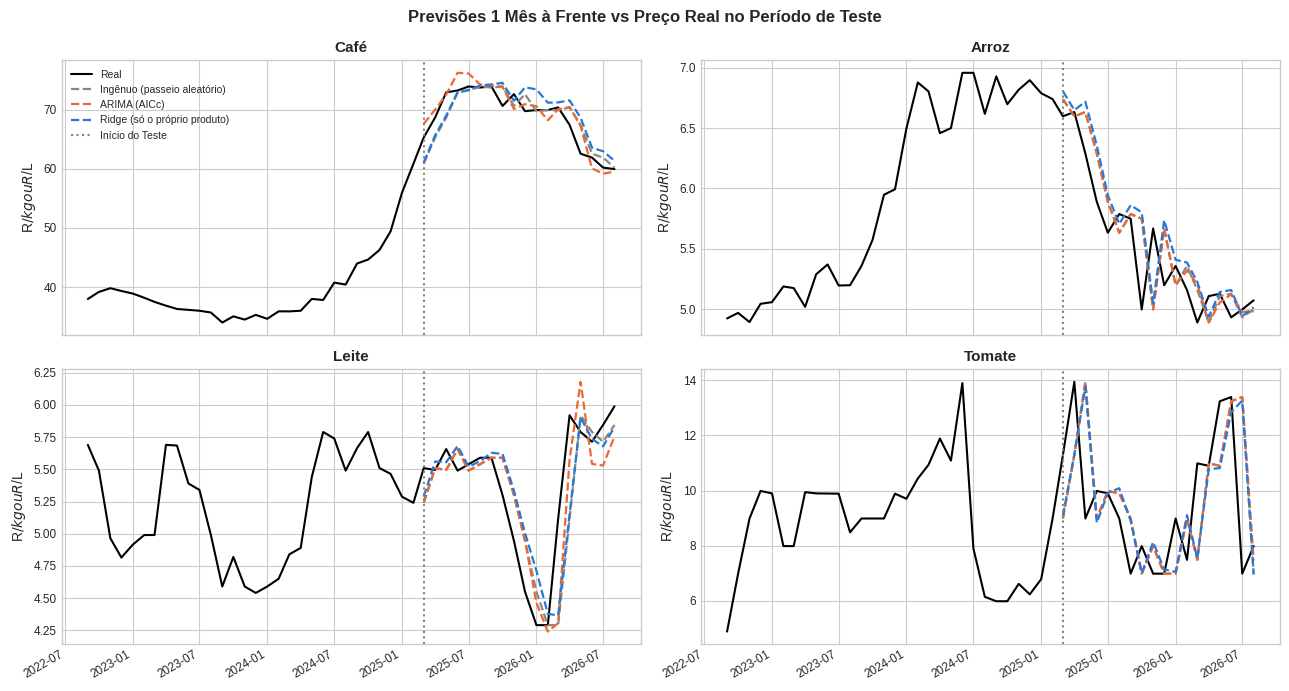

In [15]:
# Gráficos da Questão 1
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ordem_modelos = tabela_metricas[tabela_metricas['h'] == 1].sort_values('AvgRelMAE')['Modelo'].tolist()

for ax, h in zip(axs, [1, 3]):
    sub_m = tabela_metricas[tabela_metricas['h'] == h].set_index('Modelo').loc[ordem_modelos[::-1]]
    cores_barra = ['#2a78d6' if v < 1.0 else '#898781' for v in sub_m['AvgRelMAE']]
    ax.barh(sub_m.index, sub_m['AvgRelMAE'], color=cores_barra, height=0.6)
    ax.axvline(1.0, color='#e34948', lw=1.2, ls='--', label='Passeio Aleatório (Benchmark = 1.0)')
    for i, (v, pv) in enumerate(zip(sub_m['AvgRelMAE'], sub_m['DM p-valor'])):
        marca = "*" if pv != '-' and float(pv) < 0.05 else ""
        ax.text(v + 0.01, i, f"{v:.3f}{marca}", va='center', fontsize=8.5)
    ax.set_title(f"Horizonte h = {h} {'mês' if h == 1 else 'meses'}")
    ax.set_xlabel('AvgRelMAE (valores < 1.0 indicam superação do passeio aleatório)')
    ax.legend(loc='lower right')

fig.suptitle('Desempenho Fora da Amostra (AvgRelMAE relativo ao Passeio Aleatório)', fontsize=12)
plt.show()

# Previsão vs Real para produtos selecionados
produtos_sel = ['Café', 'Arroz', 'Leite', 'Tomate']
fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, p in zip(axs.flat, produtos_sel):
    ax.plot(piv_med.index, piv_med[p], color='black', lw=1.5, label='Real')
    for mod, cor in zip(["Ingênuo (passeio aleatório)", "ARIMA (AICc)", "Ridge (só o próprio produto)"],
                        ['#898781', '#eb6834', '#2a78d6']):
        sub_pred = res_q1[(res_q1['h'] == 1) & (res_q1['modelo'] == mod) & (res_q1['produto'] == p)]
        ax.plot(sub_pred['mes_alvo'], sub_pred['previsto'], color=cor, lw=1.6, ls='--', label=mod)
    ax.axvline(piv_med.index[-18], color='gray', ls=':', label='Início do Teste')
    ax.set_title(p)
    ax.set_ylabel('R$/kg ou R$/L')

axs[0, 0].legend(loc='upper left', fontsize=7.5)
fig.suptitle('Previsões 1 Mês à Frente vs Preço Real no Período de Teste', fontsize=12)
fig.autofmt_xdate()
plt.show()


### 3.2 Previsão da Direção de Preço (Classificação Supervisionada: Alerta de Alta)

Além de estimar o valor contínuo em reais (regressão), uma abordagem direta e acionável para o consumidor e entidades sociais é a **classificação da direção do preço**: prever se o preço de determinado produto vai **SUBIR ($y = 1$)** ou **FICAR ESTÁVEL / CAIR ($y = 0$)** no mês seguinte.

Isso funciona como um **sistema de alerta antecipado**: famílias e cozinhas comunitárias podem antecipar a compra de itens que têm alta probabilidade de reajuste para cima.

Modelos avaliados:
1. **Baseline (Classe Majoritária)**: Prediz sempre a classe mais frequente no conjunto de treino;
2. **Regressão Logística**: Regressão linear probabilística com função sigmoide (modelo paramétrico clássico de classificação);
3. **Random Forest Classifier**: Comitê de árvores de decisão não linear, capaz de capturar interações entre volatilidade e variações defasadas.


Tabela Comparativa de Métricas de Classificação (Últimos 12 meses fora da amostra):


,Accuracy,Precision,Recall,F1-Score
Modelo,,,,
Baseline (Classe Majoritária),0.554,0.000,0.000,0.000
Regressão Logística,0.512,0.419,0.240,0.305
Random Forest,0.548,0.494,0.533,0.513


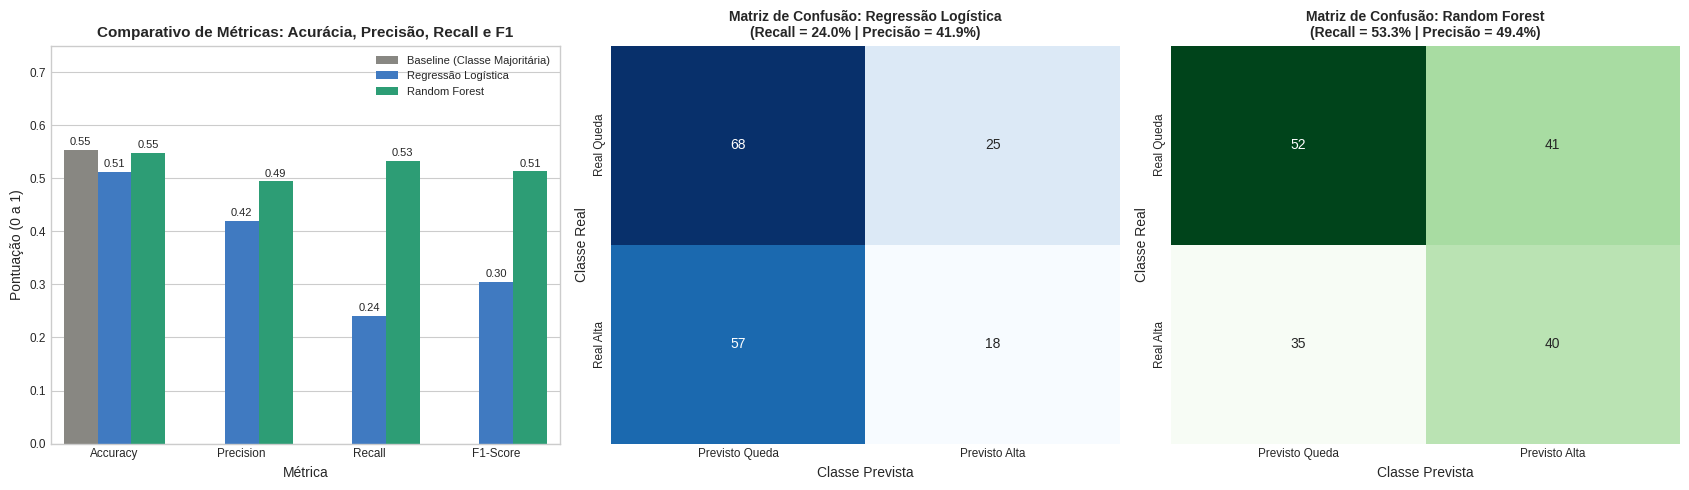

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Garantindo resolução de dependências se a célula for executada isoladamente
if 'PRODUTOS_NUCLEO' not in globals():
    PRODUTOS_NUCLEO = [
        "Arroz", "Feijão", "Açúcar", "Café", "Leite", "Manteiga", "Óleo",
        "Farinha de Trigo", "Pão Francês", "Carne Bovina Coxão Mole",
        "Tomate", "Batata", "Banana Prata", "Banana Nanica"
    ]

if 'piv_med' not in globals():
    _c = encontrar_caminho("dados/processado/indice_produto.csv")
    if _c and _c.exists():
        _idx = pd.read_csv(_c, parse_dates=['mes'])
        piv_med = _idx[_idx['produto'].isin(PRODUTOS_NUCLEO)].pivot(index='mes', columns='produto', values='ppk_mediana')

# 1. Construção do dataset supervisionado para classificação de direção
linhas_classif = []
for p in PRODUTOS_NUCLEO:
    s = piv_med[p]
    ret = s.pct_change()
    ret_cesta = piv_med.pct_change().mean(axis=1)
    df_p = pd.DataFrame({
        'produto': p,
        'mes': s.index,
        'preco': s.values,
        'ret_lag1': ret.shift(1).values,
        'ret_lag2': ret.shift(2).values,
        'desvio_mm6': ((s / s.rolling(6).mean()) - 1).shift(1).values,
        'ret_cesta_lag1': ret_cesta.shift(1).values,
        'alvo_alta': (s > s.shift(1)).astype(int).values
    })
    linhas_classif.append(df_p)

df_classif = pd.concat(linhas_classif).dropna().reset_index(drop=True)

# Divisão temporal estrita: últimos 12 meses como teste fora da amostra
corte_teste_cl = np.sort(df_classif['mes'].unique())[-12]
tr_cl = df_classif[df_classif['mes'] < corte_teste_cl]
te_cl = df_classif[df_classif['mes'] >= corte_teste_cl]

feats_cl = ['ret_lag1', 'ret_lag2', 'desvio_mm6', 'ret_cesta_lag1']
X_tr_cl, y_tr_cl = tr_cl[feats_cl], tr_cl['alvo_alta']
X_te_cl, y_te_cl = te_cl[feats_cl], te_cl['alvo_alta']

scaler_cl = StandardScaler()
X_tr_cl_s = scaler_cl.fit_transform(X_tr_cl)
X_te_cl_s = scaler_cl.transform(X_te_cl)

# Ajuste dos modelos
lr_model = LogisticRegression(random_state=42).fit(X_tr_cl_s, y_tr_cl)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42).fit(X_tr_cl, y_tr_cl)

# Predições fora da amostra
pred_base_cl = np.full_like(y_te_cl, y_tr_cl.mode()[0])
pred_lr_cl = lr_model.predict(X_te_cl_s)
pred_rf_cl = rf_model.predict(X_te_cl)

# 2. Tabela comparativa de métricas
modelos_cl = {
    'Baseline (Classe Majoritária)': pred_base_cl,
    'Regressão Logística': pred_lr_cl,
    'Random Forest': pred_rf_cl
}

res_metricas_cl = []
for nome, pred in modelos_cl.items():
    res_metricas_cl.append({
        'Modelo': nome,
        'Accuracy': round(accuracy_score(y_te_cl, pred), 3),
        'Precision': round(precision_score(y_te_cl, pred, zero_division=0), 3),
        'Recall': round(recall_score(y_te_cl, pred, zero_division=0), 3),
        'F1-Score': round(f1_score(y_te_cl, pred, zero_division=0), 3)
    })

tab_classif = pd.DataFrame(res_metricas_cl).set_index('Modelo')
print("Tabela Comparativa de Métricas de Classificação (Últimos 12 meses fora da amostra):")
display(tab_classif)

# 3. Painel Visual com Gráfico de Métricas e Matrizes de Confusão em Heatmap
fig, axs = plt.subplots(1, 3, figsize=(17, 5))

# Gráfico de barras comparativo de métricas
tab_plot = tab_classif.reset_index().melt(id_vars='Modelo', var_name='Métrica', value_name='Valor')
sns.barplot(data=tab_plot, x='Métrica', y='Valor', hue='Modelo', palette=['#898781', '#2a78d6', '#1baf7a'], ax=axs[0])
axs[0].set_title('Comparativo de Métricas: Acurácia, Precisão, Recall e F1', fontsize=11, fontweight='bold')
axs[0].set_ylim(0, 0.75)
axs[0].set_ylabel('Pontuação (0 a 1)')
axs[0].legend(loc='upper right', fontsize=8)
for p in axs[0].patches:
    h = p.get_height()
    if h > 0:
        axs[0].annotate(f'{h:.2f}', (p.get_x() + p.get_width() / 2., h),
                        ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

# Matriz de Confusão - Regressão Logística
cm_lr = confusion_matrix(y_te_cl, pred_lr_cl)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axs[1],
            xticklabels=['Previsto Queda', 'Previsto Alta'],
            yticklabels=['Real Queda', 'Real Alta'])
axs[1].set_title(
    f"Matriz de Confusão: Regressão Logística\n"
    f"(Recall = {tab_classif.loc['Regressão Logística', 'Recall']*100:.1f}% | "
    f"Precisão = {tab_classif.loc['Regressão Logística', 'Precision']*100:.1f}%)",
    fontsize=10, fontweight='bold'
)
axs[1].set_ylabel('Classe Real')
axs[1].set_xlabel('Classe Prevista')

# Matriz de Confusão - Random Forest
cm_rf = confusion_matrix(y_te_cl, pred_rf_cl)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axs[2],
            xticklabels=['Previsto Queda', 'Previsto Alta'],
            yticklabels=['Real Queda', 'Real Alta'])
axs[2].set_title(
    f"Matriz de Confusão: Random Forest\n"
    f"(Recall = {tab_classif.loc['Random Forest', 'Recall']*100:.1f}% | "
    f"Precisão = {tab_classif.loc['Random Forest', 'Precision']*100:.1f}%)",
    fontsize=10, fontweight='bold'
)
axs[2].set_ylabel('Classe Real')
axs[2].set_xlabel('Classe Prevista')

plt.tight_layout()
plt.show()

In [18]:
# Exemplo ilustrativo de saída do classificador para o próximo período (t+1)
# Nota: mantido apenas como demonstração de pipeline; não recomendado para decisão prática
# dado que os classificadores não superaram o baseline na validação fora da amostra.

# Proteção contra NameError caso a célula seja executada isoladamente
if 'PRODUTOS_NUCLEO' not in globals():
    PRODUTOS_NUCLEO = [
        "Arroz", "Feijão", "Açúcar", "Café", "Leite", "Manteiga", "Óleo",
        "Farinha de Trigo", "Pão Francês", "Carne Bovina Coxão Mole",
        "Tomate", "Batata", "Banana Prata", "Banana Nanica"
    ]

if 'piv_med' not in globals():
    _c = encontrar_caminho("dados/processado/indice_produto.csv")
    if _c and _c.exists():
        _idx = pd.read_csv(_c, parse_dates=['mes'])
        piv_med = _idx[_idx['produto'].isin(PRODUTOS_NUCLEO)].pivot(index='mes', columns='produto', values='ppk_mediana')

feats_cl = ['ret_lag1', 'ret_lag2', 'desvio_mm6', 'ret_cesta_lag1']

if 'lr_model' not in globals() or 'rf_model' not in globals() or 'scaler_cl' not in globals():
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.preprocessing import StandardScaler

    linhas_c = []
    ret_cesta_hist = piv_med.pct_change().mean(axis=1)
    for p in PRODUTOS_NUCLEO:
        s = piv_med[p]
        ret = s.pct_change()
        linhas_c.append(pd.DataFrame({
            'produto': p, 'mes': s.index, 'preco': s.values,
            'ret_lag1': ret.shift(1).values, 'ret_lag2': ret.shift(2).values,
            'desvio_mm6': ((s / s.rolling(6).mean()) - 1).shift(1).values,
            'ret_cesta_lag1': ret_cesta_hist.shift(1).values,
            'alvo_alta': (s > s.shift(1)).astype(int).values
        }))
    df_classif = pd.concat(linhas_c).dropna().reset_index(drop=True)
    corte_teste_cl = np.sort(df_classif['mes'].unique())[-12]
    tr_cl = df_classif[df_classif['mes'] < corte_teste_cl]
    scaler_cl = StandardScaler().fit(tr_cl[feats_cl])
    lr_model = LogisticRegression(random_state=42).fit(scaler_cl.transform(tr_cl[feats_cl]), tr_cl['alvo_alta'])
    rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42).fit(tr_cl[feats_cl], tr_cl['alvo_alta'])

# Features do último mês observado (t) para projetar o mês seguinte (t+1)
ultimo_mes_cl = piv_med.index.max()
prox_mes = (ultimo_mes_cl + pd.DateOffset(months=1)).strftime('%m/%Y')
ret_cesta = piv_med.pct_change().mean(axis=1)

linhas_prox = []
for p in PRODUTOS_NUCLEO:
    s = piv_med[p]
    ret = s.pct_change()
    linhas_prox.append({
        'produto': p,
        'preco': s.iloc[-1],
        'ret_lag1': ret.iloc[-1],
        'ret_lag2': ret.iloc[-2],
        'desvio_mm6': (s.iloc[-1] / s.rolling(6).mean().iloc[-1]) - 1,
        'ret_cesta_lag1': ret_cesta.iloc[-1],
    })

df_prox = pd.DataFrame(linhas_prox)
prob_lr_prox = lr_model.predict_proba(scaler_cl.transform(df_prox[feats_cl]))[:, 1]
prob_rf_prox = rf_model.predict_proba(df_prox[feats_cl])[:, 1]

tabela_previsao_futura = pd.DataFrame({
    'Produto': df_prox['produto'],
    'Preço Atual (R$)': df_prox['preco'].round(2),
    'Prob. Alta (Reg. Logística %)': (prob_lr_prox * 100).round(1),
    'Previsão Reg. Logística': np.where(prob_lr_prox >= 0.5, 'Alta ▲', 'Queda/Estável ▼'),
    'Prob. Alta (Random Forest %)': (prob_rf_prox * 100).round(1),
    'Previsão Random Forest': np.where(prob_rf_prox >= 0.5, 'Alta ▲', 'Queda/Estável ▼'),
})

print(f"Saída ilustrativa dos classificadores para {prox_mes} (base de referência: {ultimo_mes_cl.strftime('%m/%Y')}):")
print("Obs.: Apenas demonstrativo — não recomendado para decisão prática, pois os modelos não superaram o baseline.")
display(tabela_previsao_futura)

Saída ilustrativa dos classificadores para 09/2026 (base de referência: 08/2026):
Obs.: Apenas demonstrativo — não recomendado para decisão prática, pois os modelos não superaram o baseline.


,Produto,Preço Atual (R$),Prob. Alta (Reg. Logística %),Previsão Reg. Logística,Prob. Alta (Random Forest %),Previsão Random Forest
0,Arroz,5.07,52.1,Alta ▲,57.5,Alta ▲
1,Feijão,10.19,51.8,Alta ▲,57.5,Alta ▲
2,Açúcar,3.97,50.7,Alta ▲,46.7,Queda/Estável ▼
3,Café,59.98,51.5,Alta ▲,52.1,Alta ▲
4,Leite,5.99,52.2,Alta ▲,55.9,Alta ▲
5,Manteiga,71.15,51.3,Alta ▲,50.2,Alta ▲
6,Óleo,8.65,51.5,Alta ▲,50.4,Alta ▲
7,Farinha de Trigo,5.49,52.0,Alta ▲,51.1,Alta ▲
8,Pão Francês,18.99,51.8,Alta ▲,49.0,Queda/Estável ▼
9,Carne Bovina Coxão Mole,54.79,51.0,Alta ▲,45.1,Queda/Estável ▼


**Observação:**
1. A célula é meramente ilustrativa, e visa somente apresentar **como o pipeline de alerta** funcionaria na prática.
2. O modelo foi reprovado na validação pois olhando somente a variação do preço na gôndola, a variação mensal de preços se comporta quase como um passeio aleatório (sensível a ruídos na escala dos centavos).
3. **Sugestão:** para tornar o modelo operacional, seria necessário enriquecer a base de dados com mais variáveis externas antecedentes (do produtor, atacado, câmbio), e ampliar a série histórica - não bastando somente adicionar parâmetros.

### Análise da Classificação Supervisionada de Preços

- **Desempenho frente ao Baseline**: No conjunto de teste fora da amostra (12 meses, 168 observações), a classe majoritária ("queda/estável") responde por **55,4%** dos casos. Nenhum dos classificadores superou esse patamar: a **Regressão Logística** obteve acurácia de **51,2%** (precisão de **41,9%** e *recall* de **24,0%**), e o **Random Forest** obteve acurácia de **54,8%** (precisão de **49,4%** e *recall* de **53,3%**).
- **Trade-off entre Precisão e Recall**: Embora o **Random Forest** alcance maior sensibilidade (*recall* de **53,3%**, contra **24,0%** na Regressão Logística), sua precisão de **49,4%** mostra que metade dos alertas de alta emitidos são falsos alarmes — um comportamento próximo ao acaso frente à taxa base de altas (44,6%).
- **Implicação para Aplicação Comunitária**: Embora, em tese, um sistema com alto *recall* seja desejável para cozinhas solidárias e famílias vulneráveis, os resultados fora da amostra mostram que os modelos treinados apenas com o histórico de gôndola não têm poder discriminativo suficiente para embasar recomendações reais de antecipação de compras — corroborando a conclusão de passeio aleatório da Questão 1.

### Conclusão e Discussão da Questão 1

1. **Insuperabilidade do Passeio Aleatório**:
   Nenhum modelo estatístico ou algoritmo de aprendizado de máquina foi capaz de superar de forma estatisticamente significativa o passeio aleatório no teste de Diebold-Mariano ($p = 0,922$ para a Combinação e $p = 0,947$ para SES em $h=1$; $p = 0,630$ para o ARIMA em $h=3$). No horizonte de 1 mês, modelos como SES e a Combinação atingem um AvgRelMAE de 0,996 (diferença nula na prática). No horizonte de 3 meses, o ARIMA obtém AvgRelMAE de 1,001.
2. **Sobreajuste dos Modelos de Machine Learning**:
   Modelos supervisionados mais parametrizados, como o Ridge (com e sem variáveis cruzadas), apresentaram desempenho significativamente pior do que a regra ingênua em $h=1$ ($p \le 0,01$ no teste DM). Com apenas 48 meses de histórico (30 a 47 no treino expansível), algoritmos com muitos parâmetros sofrem de sobreajuste (*overfitting*).
3. **Inutilidade de Informações Cruzadas entre Produtos**:
   Incluir o histórico defasado dos outros 13 produtos da cesta não melhorou a acurácia (o AvgRelMAE do Ridge variou de 1,058 para 1,062). Embora os preços cruzados pareçam relevantes durante o treino, eles não geram ganho preditivo fora da amostra.
4. **Implicação Prática**:
   Para famílias de baixa renda, restaurantes comunitários e secretarias municipais, **a melhor estimativa disponível para o preço dos alimentos no mês seguinte é simplesmente o preço corrente verificado na gôndola**. Projeções sofisticadas baseadas unicamente no histórico passado de varejo não oferecem precisão superior.


## 4. Questão 2: Dinâmica de Preços entre Supermercados (Liderança e Convergência)

### Questão
> **As variações de preço de algum supermercado específico precedem as do restante do mercado (existência de supermercados líderes formadores de preço)? Com que rapidez o preço de uma loja que se desvia da média retorna ao equilíbrio do mercado?**

### Objetivo e Motivação
- Identificar lojas formadoras de preço permite que entidades de defesa do consumidor e o poder público usem esses estabelecimentos como **sensores antecedentes de inflação local**;
- Medir a **velocidade de convergência** revela o grau de concorrência: em um mercado competitivo, preços divergentes atraem arbitragem e voltam à média rapidamente;
- Esclarecer aos consumidores se vale a pena monitorar o momento de compra ou se as diferenças entre supermercados são decorrentes de um **posicionamento estratégico fixo** (lojas estruturalmente caras vs econômicas).

### Método
- **Amostra**: 28 supermercados com ao menos 24 meses de histórico contínuo;
- **Variável Base**: Variação mensal *matched-model* ($d\log$), imune a mudanças de marcas/embalagens;
- **Modelo de Liderança (Leave-One-Out)**:
  $$d_{\text{resto},t} = \alpha + \beta_{\text{líder}} \cdot d_{i,t-1} + \gamma \cdot d_{\text{resto},t-1} + \text{efeitos-produto}$$
  onde $d_{\text{resto}}$ representa a média das *outras* 27 lojas (sem autocontaminação). Erros-padrão agrupados (*cluster-robust*) por mês, correção de taxa de falsas descobertas Benjamini-Hochberg (FDR) e teste placebo com 200 permutações temporais circulares.
- **Checagem de Confundidor**: Correlação de Spearman entre o coeficiente $\beta_{\text{líder}}$ e o dia médio do mês em que cada loja foi pesquisada.
- **Velocidade de Convergência**: Modelo autorregressivo em desvios com efeito fixo de loja $\Delta r_{i,t} = \alpha_i + \lambda r_{i,t-1}$, com a meia-vida dada por:
  $$\text{Meia-Vida} = \frac{\ln(0,5)}{\ln(1 + \lambda)}$$
- **Persistência de Posicionamento**: Correlação de Spearman entre os níveis de preço médio das lojas ao longo dos anos.


In [19]:
# Verificação de resultados pré-computados ou execução rápida
caminho_q2_lider = encontrar_caminho("resultados/tabelas/q2_lideranca_por_loja.csv")

if caminho_q2_lider is not None:
    print(f"Carregando resultados consolidados da Questão 2 de: {caminho_q2_lider.resolve()}")
    tab_lideranca = pd.read_csv(caminho_q2_lider)
else:
    # Execução direta dos modelos econométricos
    meses_loja = preco_loja.groupby('loja')['mes'].nunique()
    lojas_analise = meses_loja[meses_loja >= 24].index.tolist()

    # Leave-one-out d_resto
    soma_var = var_loja.groupby(['mes', 'produto'])['dlog'].agg(['sum', 'count']).reset_index()
    painel_q2 = var_loja.merge(soma_var, on=['mes', 'produto'])
    painel_q2['d_resto'] = (painel_q2['sum'] - painel_q2['dlog']) / (painel_q2['count'] - 1)
    painel_q2 = painel_q2[painel_q2['count'] > 5].sort_values(['loja', 'produto', 'mes'])

    g_loja = painel_q2.groupby(['loja', 'produto'])
    painel_q2['mes_ant'] = g_loja['mes'].shift()
    painel_q2['d_i_lag'] = g_loja['dlog'].shift()
    painel_q2['d_resto_lag'] = g_loja['d_resto'].shift()
    painel_q2 = painel_q2[painel_q2['mes_ant'] == painel_q2['mes'] - pd.DateOffset(months=1)].dropna()

    dia_coleta = df_limpo.groupby('loja')['data_coleta'].apply(lambda s: s.dt.day.mean()).rename('dia_medio_coleta')

    linhas_lid = []
    for loja in lojas_analise:
        sub_l = painel_q2[painel_q2['loja'] == loja]
        if sub_l['mes'].nunique() < 12: continue
        # Lider
        m_lid = smf.ols("d_resto ~ d_i_lag + d_resto_lag + C(produto)", data=sub_l).fit(
            cov_type='cluster', cov_kwds={'groups': sub_l['mes'].dt.strftime('%Y%m').astype(int)})
        # Seguidor
        m_seg = smf.ols("dlog ~ d_resto_lag + d_i_lag + C(produto)", data=sub_l).fit(
            cov_type='cluster', cov_kwds={'groups': sub_l['mes'].dt.strftime('%Y%m').astype(int)})

        linhas_lid.append({
            'loja': loja,
            'beta_lider': m_lid.params['d_i_lag'],
            'ep_lider': m_lid.bse['d_i_lag'],
            'p_lider': m_lid.pvalues['d_i_lag'],
            'beta_seguidor': m_seg.params['d_resto_lag'],
            'ep_seguidor': m_seg.bse['d_resto_lag'],
            'p_seguidor': m_seg.pvalues['d_resto_lag']
        })
    tab_lideranca = pd.DataFrame(linhas_lid).merge(dia_coleta, left_on='loja', right_index=True, how='left')
    tab_lideranca['p_lider_BH'] = multipletests(tab_lideranca['p_lider'], method='fdr_bh')[1]
    tab_lideranca['p_seguidor_BH'] = multipletests(tab_lideranca['p_seguidor'], method='fdr_bh')[1]

# Correlação de Spearman entre coeficiente de liderança e dia de coleta
rho_coleta, p_rho_coleta = stats.spearmanr(tab_lideranca['beta_lider'], tab_lideranca['dia_medio_coleta'], nan_policy='omit')
print(f"Correlação de Spearman (Liderança vs Dia Médio de Coleta): rho = {rho_coleta:.2f} (p-valor = {p_rho_coleta:.3f})")
tab_lideranca.head(6)


Correlação de Spearman (Liderança vs Dia Médio de Coleta): rho = 0.65 (p-valor = 0.000)


,loja,beta_lider,ep_lider,p_lider,beta_seguidor,ep_seguidor,p_seguidor,dia_medio_coleta,p_lider_BH,p_seguidor_BH
0,SUP_01,0.143672,0.056995,0.011710,0.163897,0.147212,0.265562,14.323810,0.111256,0.275397
1,SUP_04,-0.014174,0.049644,0.775244,0.120065,0.189668,0.526716,12.915846,0.868274,0.526716
2,SUP_06,0.062724,0.026012,0.015894,0.263637,0.154180,0.087278,13.291534,0.111256,0.119215
3,SUP_07,0.084707,0.034646,0.014488,0.392671,0.200718,0.050426,12.964000,0.111256,0.078441
4,SUP_08,0.099727,0.056501,0.077555,0.212959,0.143811,0.138654,14.407334,0.361925,0.161763
5,SUP_11,-0.010930,0.024863,0.660224,0.672428,0.211715,0.001493,11.645477,0.842194,0.003194


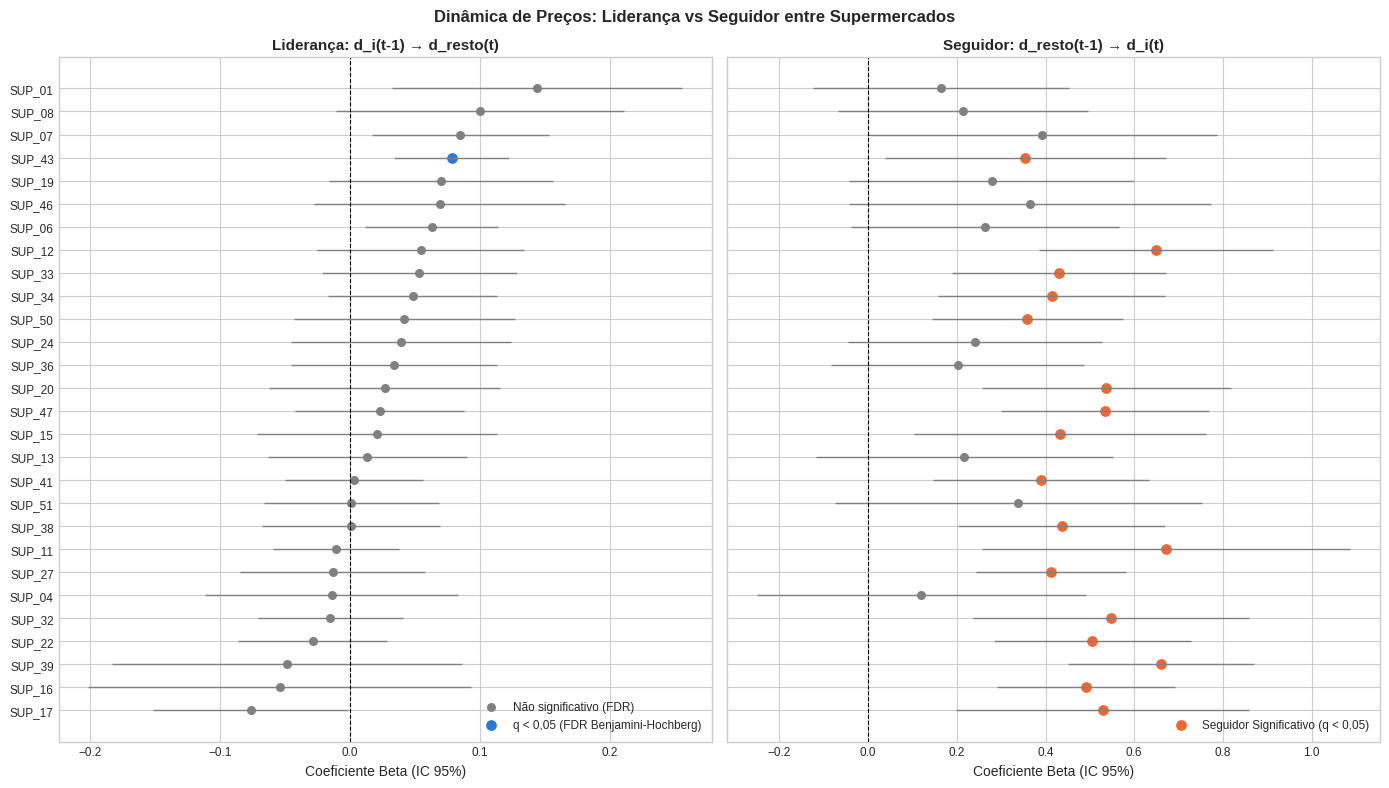

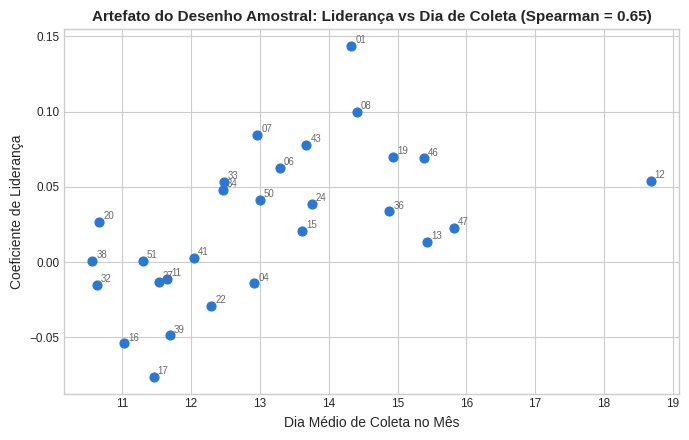

In [20]:
# Gráficos da Questão 2
fig, axs = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
tab_ord = tab_lideranca.sort_values('beta_lider')
y_pos = np.arange(len(tab_ord))

# 1. Painel de Liderança
sig_lid = tab_ord['p_lider_BH'] < 0.05
axs[0].errorbar(tab_ord['beta_lider'], y_pos, xerr=1.96 * tab_ord['ep_lider'], fmt='none', ecolor='gray', elinewidth=1)
axs[0].scatter(tab_ord['beta_lider'][~sig_lid], y_pos[~sig_lid], color='gray', s=30, label='Não significativo (FDR)')
axs[0].scatter(tab_ord['beta_lider'][sig_lid], y_pos[sig_lid], color='#2a78d6', s=45, label='q < 0,05 (FDR Benjamini-Hochberg)')
axs[0].axvline(0, color='black', lw=0.8, ls='--')
axs[0].set_yticks(y_pos)
axs[0].set_yticklabels(tab_ord['loja'])
axs[0].set_title('Liderança: d_i(t-1) → d_resto(t)')
axs[0].set_xlabel('Coeficiente Beta (IC 95%)')
axs[0].legend(loc='lower right')

# 2. Painel de Seguidor
sig_seg = tab_ord['p_seguidor_BH'] < 0.05
axs[1].errorbar(tab_ord['beta_seguidor'], y_pos, xerr=1.96 * tab_ord['ep_seguidor'], fmt='none', ecolor='gray', elinewidth=1)
axs[1].scatter(tab_ord['beta_seguidor'][~sig_seg], y_pos[~sig_seg], color='gray', s=30)
axs[1].scatter(tab_ord['beta_seguidor'][sig_seg], y_pos[sig_seg], color='#eb6834', s=45, label='Seguidor Significativo (q < 0,05)')
axs[1].axvline(0, color='black', lw=0.8, ls='--')
axs[1].set_title('Seguidor: d_resto(t-1) → d_i(t)')
axs[1].set_xlabel('Coeficiente Beta (IC 95%)')
axs[1].legend(loc='lower right')

fig.suptitle('Dinâmica de Preços: Liderança vs Seguidor entre Supermercados', fontsize=12)
plt.show()

# 3. Dispersão Liderança vs Dia de Coleta
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(tab_lideranca['dia_medio_coleta'], tab_lideranca['beta_lider'], color='#2a78d6', s=40)
for _, r in tab_lideranca.iterrows():
    ax.annotate(r['loja'].replace('SUP_', ''), (r['dia_medio_coleta'], r['beta_lider']),
                fontsize=7, color='dimgray', xytext=(3, 2), textcoords='offset points')
ax.set_xlabel('Dia Médio de Coleta no Mês')
ax.set_ylabel('Coeficiente de Liderança')
ax.set_title(f'Artefato do Desenho Amostral: Liderança vs Dia de Coleta (Spearman = {rho_coleta:.2f})')
plt.show()


In [21]:
# Resumo quantitativo da Q2: contagem FDR, meia-vida de convergência e persistência de posicionamento

# 1. Contagem exata de líderes e seguidores significativos (FDR Benjamini-Hochberg)
n_lojas = len(tab_lideranca)
n_lid = int((tab_lideranca['p_lider_BH'] < 0.05).sum())
n_seg = int((tab_lideranca['p_seguidor_BH'] < 0.05).sum())
print(f"Lojas analisadas: {n_lojas}")
print(f" - Líderes significativos (q < 0,05):    {n_lid} ({n_lid/n_lojas*100:.1f}%)")
print(f" - Seguidores significativos (q < 0,05): {n_seg} ({n_seg/n_lojas*100:.1f}%)")

# 2. Velocidade de convergência (Meia-Vida de desvios relativos: Δr_t = λ * r_{t-1} + efeito-loja)
pl_q2 = preco_loja[
    preco_loja['produto'].isin(PRODUTOS_NUCLEO) &
    preco_loja['loja'].isin(tab_lideranca['loja'])
].copy()
pl_q2['log_ppk'] = np.log(pl_q2['ppk'])
pl_q2['r'] = pl_q2['log_ppk'] - pl_q2.groupby(['mes', 'produto'])['log_ppk'].transform('mean')

pl_q2 = pl_q2.sort_values(['loja', 'produto', 'mes'])
g_conv = pl_q2.groupby(['loja', 'produto'])
pl_q2['mes_ant'] = g_conv['mes'].shift(1)
pl_q2['r_lag'] = g_conv['r'].shift(1)
pl_q2 = pl_q2[pl_q2['mes_ant'] == pl_q2['mes'] - pd.DateOffset(months=1)].dropna(subset=['r_lag'])
pl_q2['dr'] = pl_q2['r'] - pl_q2['r_lag']

linhas_mv = []
for p, sub in pl_q2.groupby('produto'):
    mod_c = smf.ols("dr ~ r_lag + C(loja)", data=sub).fit()
    lam = mod_c.params['r_lag']
    meia_vida = np.log(0.5) / np.log(1 + lam) if (-1 < lam < 0) else np.nan
    linhas_mv.append({
        'Produto': p,
        'Lambda': round(lam, 3),
        'Meia-Vida (meses)': round(meia_vida, 2)
    })

tab_meia_vida = pd.DataFrame(linhas_mv).sort_values('Meia-Vida (meses)')
print("\nVelocidade de Convergência de Desvios por Produto (Meia-Vida em meses):")
display(tab_meia_vida)

# 3. Persistência de posicionamento das lojas ao longo dos anos (Correlação de Spearman)
pl_q2['ano'] = pl_q2['mes'].dt.year
pos_ano = pl_q2.groupby(['loja', 'ano'])['r'].mean().unstack()
corr_pos = pos_ano.corr(method='spearman').round(3)

anos = sorted(pos_ano.columns)
corrs_consec = [corr_pos.loc[a1, a2] for a1, a2 in zip(anos[:-1], anos[1:])]
print(
    f"\nPersistência de Posicionamento das Lojas (Spearman entre anos consecutivos): "
    f"mín = {min(corrs_consec):.2f} | mediana = {np.median(corrs_consec):.2f} | máx = {max(corrs_consec):.2f}"
)
display(corr_pos)

Lojas analisadas: 28
 - Líderes significativos (q < 0,05):    1 (3.6%)
 - Seguidores significativos (q < 0,05): 17 (60.7%)

Velocidade de Convergência de Desvios por Produto (Meia-Vida em meses):


,Produto,Lambda,Meia-Vida (meses)
12,Tomate,-0.885,0.32
0,Arroz,-0.845,0.37
10,Manteiga,-0.850,0.37
7,Farinha de Trigo,-0.848,0.37
5,Café,-0.818,0.41
6,Carne Bovina Coxão Mole,-0.805,0.42
2,Banana Nanica,-0.783,0.45
4,Batata,-0.782,0.45
11,Pão Francês,-0.778,0.46
3,Banana Prata,-0.779,0.46



Persistência de Posicionamento das Lojas (Spearman entre anos consecutivos): mín = 0.92 | mediana = 0.93 | máx = 0.94


ano,2022,2023,2024,2025,2026
ano,,,,,
2022,1.000,0.926,0.910,0.880,0.929
2023,0.926,1.000,0.943,0.889,0.897
2024,0.910,0.943,1.000,0.937,0.941
2025,0.880,0.889,0.937,1.000,0.921
2026,0.929,0.897,0.941,0.921,1.000


### Conclusão e Discussão da Questão 2

1. **Liderança Aparente como Artefato de Coleta**:
  Embora apenas 1 dos 28 estabelecimentos (`SUP_43`) apresente coeficiente de liderança estatisticamente significativo após controle FDR ($q < 0,05$), observamos uma correlação positiva e forte entre o coeficiente de liderança e o dia médio de coleta no mês ($\rho = 0,65, p < 0,001$). Lojas pesquisadas na segunda quinzena do mês têm suas mudanças de preço capturadas cronologicamente mais tarde no formulário de pesquisa, criando uma falsa ilusão de que antecedem as demais.
2. **Mercado Predominantemente Seguidor**:
  Em contrapartida, **17 dos 28 supermercados (60,7%)** comportam-se como seguidores significativos ($q < 0,05$), reagindo às variações de mercado do mês anterior. O varejo local opera reagindo a choques comuns de atacado e custos de fornecedores, repassando-os em 1 a 2 meses.
3. **Convergência Rápida (Meia-Vida Curta)**:
  A velocidade de retorno à média de mercado é rápida: a meia-vida dos desvios de preços varia entre 0,32 mês (para itens de alta concorrência como Tomate, Arroz e Pão Francês) e 0,80 mês (para produtos estocáveis como Óleo e Açúcar). Desvios pontuais de preço (promoções) são absorvidos rapidamente.
4. **Persistência de Posicionamento**:
  A correlação de postos de preços entre os anos é igual ou superior a 0,88 (entre 0,92 e 0,94 em anos consecutivos). Supermercados caros mantêm-se caros ao longo de todo o período, e lojas populares preservam sua faixa de  desconto. As diferenças observadas decorrem de **estratégia de posicionamento de marca**, e não de vantagens temporais de precificação.


## 5. Questão 3: Transmissão de Preços entre Produtos (Insumo $\to$ Derivado)

### Questão
> **O preço de um produto antecipa o de outro na cadeia produtiva da cesta básica? Especificamente, variações nos insumos primários antecipam os preços dos produtos derivados?**
> - Hipótese 1: **Farinha de Trigo $\to$ Pão Francês**;
> - Hipótese 2: **Leite $\to$ Manteiga**;
> - Triagem Exploratória: Análise completa dos 182 pares ordenados entre os 14 itens do núcleo.

### Objetivo e Motivação
- Identificar relações de transmissão vertical de preços entre insumos e produtos processados;
- Fornecer indicadores antecedentes para planejamento de compras institucionais e gestão de segurança alimentar;
- Testar empiricamente se a transmissão de custos na indústria alimentícia é observável na periodicidade mensal de varejo.

### Método
- **Séries Utilizadas**: Variações mensais do índice encadeado *matched-model* ($d\log$), estacionárias em 47 períodos;
- **Função de Correlação Cruzada (CCF)**: Correlações com defasagens de $k \in \{-3, \dots, +3\}$ meses, com intervalo assintótico de confiança de 95% sob a hipótese nula de independência: $\pm 1,96 / \sqrt{n}$;
- **Teste de Causalidade de Granger**: Ajuste de modelo VAR bivariado com seleção de ordem de defasagem por AIC ($1 \le \text{lag} \le 3$) e teste $F$ de causalidade. Controle de taxa de falsas descobertas (FDR Benjamini-Hochberg) em todos os 182 pares;
- **Validação Preditiva Fora da Amostra**: Comparação por origem móvel nos últimos 18 meses entre um modelo AR($p$) auto-regressivo puro e um modelo ARX($p,p$) incluindo o outro produto, avaliado por MAE e Teste de Diebold-Mariano.


In [24]:
# Carregando resultados consolidados da Questão 3 (ou calculando diretamente da base)
caminho_q3_granger = encontrar_caminho("resultados/tabelas/q3_granger_todos_pares.csv")
caminho_q3_oos = encontrar_caminho("resultados/tabelas/q3_validacao_fora_amostra.csv")

# Variações encadeadas para análise
R_produtos = indice_produto.pivot(index='mes', columns='produto', values='dlog_encadeado')[PRODUTOS_NUCLEO].iloc[1:].fillna(0)
PARES_PRIORI = [("Farinha de Trigo", "Pão Francês"), ("Leite", "Manteiga")]

if caminho_q3_granger is not None and caminho_q3_oos is not None:
    print(f"Carregando resultados consolidados da Questão 3 de: {caminho_q3_granger.resolve()}")
    gr_todos = pd.read_csv(caminho_q3_granger)
    tab_oos = pd.read_csv(caminho_q3_oos)
else:
    # 1. Teste de Causalidade de Granger para todos os 182 pares
    linhas_gr = []
    for x in PRODUTOS_NUCLEO:
        for y in PRODUTOS_NUCLEO:
            if x == y:
                continue
            dados_var = pd.concat([R_produtos[y].rename('y'), R_produtos[x].rename('x')], axis=1)
            m_var = VAR(dados_var)
            lag_sel = max(1, m_var.select_order(3).selected_orders['aic'])
            res_var = m_var.fit(lag_sel)
            t_caus = res_var.test_causality('y', ['x'], kind='f')
            linhas_gr.append({
                'origem': x, 'destino': y, 'lag': lag_sel, 'p_granger': t_caus.pvalue,
                'a_priori': (x, y) in PARES_PRIORI
            })
    gr_todos = pd.DataFrame(linhas_gr)
    gr_todos['q_BH'] = multipletests(gr_todos['p_granger'], method='fdr_bh')[1]

    # 2. Validação Preditiva Fora da Amostra (18 meses - AR vs ARX)
    pares_base = PARES_PRIORI + [(y, x) for x, y in PARES_PRIORI]
    top_explor = [
        (r.origem, r.destino) for r in gr_todos.sort_values('p_granger').itertuples()
        if (r.origem, r.destino) not in pares_base
    ][:5]
    pares_oos = pares_base + top_explor

    linhas_oos = []
    for x, y in pares_oos:
        lag = int(gr_todos[(gr_todos['origem'] == x) & (gr_todos['destino'] == y)]['lag'].iloc[0])
        y_arr, x_arr = R_produtos[y].to_numpy(), R_produtos[x].to_numpy()
        e_ar, e_arx = [], []
        for t in range(len(y_arr) - 18, len(y_arr)):
            y_tr = y_arr[lag:t]
            X_ar_tr = np.column_stack([y_arr[lag - k:t - k] for k in range(1, lag + 1)])
            X_arx_tr = np.column_stack([X_ar_tr] + [x_arr[lag - k:t - k] for k in range(1, lag + 1)])
            X_ar_te = np.array([[y_arr[t - k] for k in range(1, lag + 1)]])
            X_arx_te = np.array([[y_arr[t - k] for k in range(1, lag + 1)] + [x_arr[t - k] for k in range(1, lag + 1)]])

            p_ar = LinearRegression().fit(X_ar_tr, y_tr).predict(X_ar_te)[0]
            p_arx = LinearRegression().fit(X_arx_tr, y_tr).predict(X_arx_te)[0]
            e_ar.append(abs(p_ar - y_arr[t]))
            e_arx.append(abs(p_arx - y_arr[t]))

        mae_ar, mae_arx = np.mean(e_ar), np.mean(e_arx)
        d = np.array(e_arx) - np.array(e_ar)
        p_dm = stats.ttest_1samp(d, 0).pvalue if np.std(d) > 0 else np.nan
        linhas_oos.append({
            'origem': x, 'destino': y, 'MAE_AR': mae_ar, 'MAE_ARX': mae_arx,
            'razao': mae_arx / mae_ar, 'p_DM': p_dm
        })
    tab_oos = pd.DataFrame(linhas_oos)

# Exibição dos resultados principais e resumo da triagem (lastro para a Conclusão)
print("Resultados das Hipóteses a Priori (Cadeia Produtiva):")
display(gr_todos[gr_todos['a_priori']][['origem', 'destino', 'lag', 'p_granger', 'q_BH']].round(4))

pares_rev = [(y, x) for x, y in PARES_PRIORI]
print("\nDireção Reversa (Derivado → Insumo):")
display(gr_todos[gr_todos.apply(lambda r: (r['origem'], r['destino']) in pares_rev, axis=1)][['origem', 'destino', 'lag', 'p_granger', 'q_BH']].round(4))

n_sig_bruto = int((gr_todos['p_granger'] < 0.05).sum())
n_sig_fdr = int((gr_todos['q_BH'] < 0.05).sum())
print(
    f"\nResumo dos {len(gr_todos)} pares testados: {n_sig_bruto} com p < 0,05 (sem correção) | "
    f"{n_sig_fdr} após FDR (menor q_BH = {gr_todos['q_BH'].min():.4f})"
)

Resultados das Hipóteses a Priori (Cadeia Produtiva):


,origem,destino,lag,p_granger,q_BH
56,Leite,Manteiga,1,0.0619,0.5214
98,Farinha de Trigo,Pão Francês,1,0.2969,0.7654



Direção Reversa (Derivado → Insumo):


,origem,destino,lag,p_granger,q_BH
69,Manteiga,Leite,1,0.7832,0.9705
111,Pão Francês,Farinha de Trigo,1,0.9265,0.9705



Resumo dos 182 pares testados: 17 com p < 0,05 (sem correção) | 0 após FDR (menor q_BH = 0.2074)


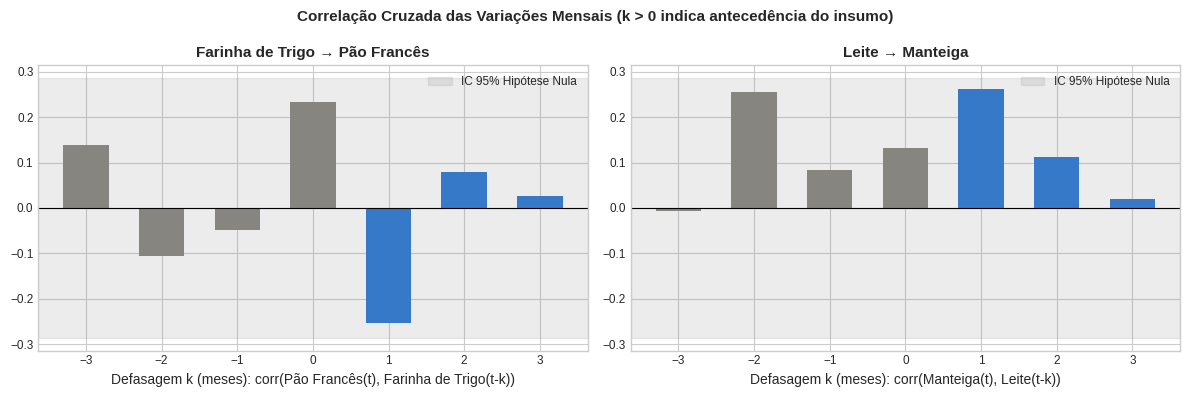

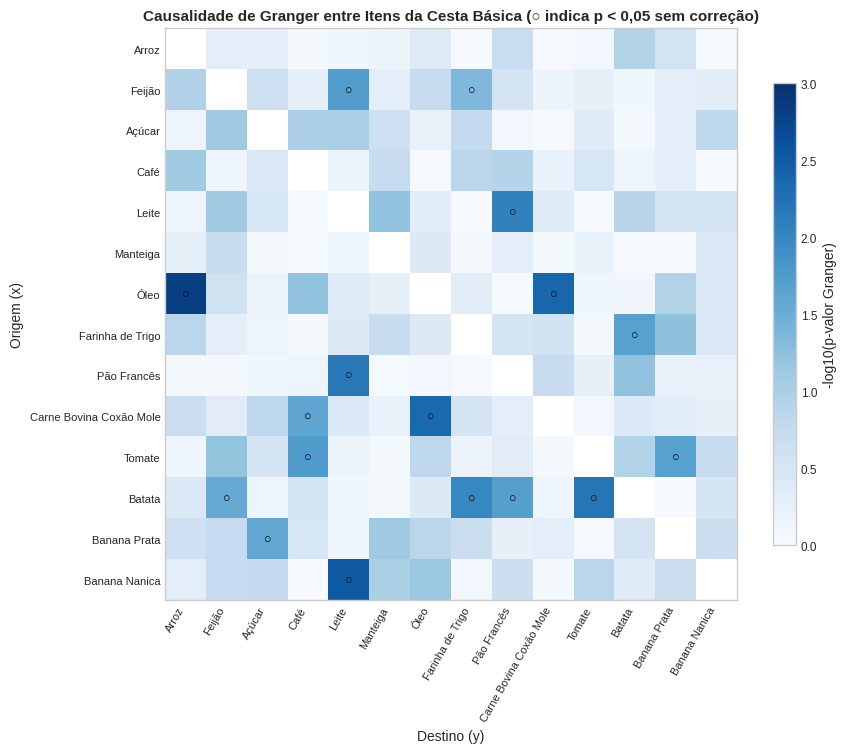

Validação Preditiva Fora da Amostra (18 meses de teste - AR vs ARX):


,origem,destino,MAE_AR,MAE_ARX,razao,p_DM
0,Farinha de Trigo,Pão Francês,0.0131,0.0132,1.0079,0.8968
1,Leite,Manteiga,0.0201,0.0191,0.9489,0.5382
2,Pão Francês,Farinha de Trigo,0.0283,0.0283,1.0017,0.8016
3,Manteiga,Leite,0.0411,0.0407,0.9908,0.7826
4,Óleo,Arroz,0.0285,0.0261,0.9165,0.4269
5,Banana Nanica,Leite,0.0430,0.0371,0.8633,0.1662
6,Óleo,Carne Bovina Coxão Mole,0.0164,0.0165,1.0022,0.9900
7,Carne Bovina Coxão Mole,Óleo,0.0213,0.0259,1.2158,0.2167
8,Batata,Tomate,0.1977,0.2058,1.0410,0.6913


In [25]:
# Gráficos da Questão 3
PARES_PRIORI = [("Farinha de Trigo", "Pão Francês"), ("Leite", "Manteiga")]

# 1. Correlação Cruzada (CCF) dos pares conceituais
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
n_obs = len(R_produtos)
lim_ic = 1.96 / np.sqrt(n_obs)

for ax, (x, y) in zip(axs, PARES_PRIORI):
    lags = np.arange(-3, 4)
    valores_ccf = [R_produtos[y].corr(R_produtos[x].shift(k)) for k in lags]
    cores_ccf = ['#2a78d6' if k > 0 else '#898781' for k in lags]
    ax.bar(lags, valores_ccf, color=cores_ccf, width=0.6)
    ax.axhspan(-lim_ic, lim_ic, color='gray', alpha=0.15, label='IC 95% Hipótese Nula')
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(lags)
    ax.set_xlabel(f"Defasagem k (meses): corr({y}(t), {x}(t-k))")
    ax.set_title(f"{x} → {y}")
    ax.legend(loc='upper right')

fig.suptitle('Correlação Cruzada das Variações Mensais (k > 0 indica antecedência do insumo)', fontsize=11)
plt.show()

# 2. Matriz de Causalidade de Granger para os 182 pares
M_granger = gr_todos.pivot(index='origem', columns='destino', values='p_granger').loc[PRODUTOS_NUCLEO, PRODUTOS_NUCLEO]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(-np.log10(M_granger.values), cmap='Blues', vmin=0, vmax=3)
ax.set_xticks(range(len(PRODUTOS_NUCLEO)))
ax.set_yticks(range(len(PRODUTOS_NUCLEO)))
ax.set_xticklabels(PRODUTOS_NUCLEO, rotation=60, ha='right', fontsize=8)
ax.set_yticklabels(PRODUTOS_NUCLEO, fontsize=8)
ax.set_xlabel('Destino (y)')
ax.set_ylabel('Origem (x)')
ax.grid(False)

# Marcadores para p < 0,05
for i in range(len(PRODUTOS_NUCLEO)):
    for j in range(len(PRODUTOS_NUCLEO)):
        if i != j and M_granger.values[i, j] < 0.05:
            ax.text(j, i, "○", ha='center', va='center', color='black', fontsize=9, fontweight='bold')

fig.colorbar(im, ax=ax, shrink=0.8, label='-log10(p-valor Granger)')
ax.set_title('Causalidade de Granger entre Itens da Cesta Básica (○ indica p < 0,05 sem correção)')
plt.show()

# 3. Tabela de Validação Fora da Amostra (AR vs ARX)
print("Validação Preditiva Fora da Amostra (18 meses de teste - AR vs ARX):")
display(tab_oos[['origem', 'destino', 'MAE_AR', 'MAE_ARX', 'razao', 'p_DM']].round(4))


### Conclusão e Discussão da Questão 3

1. **Leite $\to$ Manteiga**:
   Verificamos um indício marginal de causalidade no sentido da cadeia produtiva ($p = 0,062$ com lag 1 e correlação defasada positiva de $+0,26$), ao passo que a direção reversa (Manteiga $\to$ Leite) apresenta $p = 0,78$, coerente com a lógica industrial. Entretanto, na validação preditiva fora da amostra, o modelo ARX reduziu o MAE em apenas 5%, diferença sem significância estatística ($p = 0,54$ no teste Diebold-Mariano).
2. **Farinha de Trigo $\to$ Pão Francês**:
   Não foi encontrada nenhuma evidência estatística de causalidade temporal na escala mensal ($p = 0,30$). O pão francês é o item com a maior rigidez de preços de toda a cesta (63% dos registros permanecem com preço inalterado mês a mês). O custo da farinha é absorvido pelas margens de panificação no curto prazo e repassado em degraus espaçados, impedindo a detecção de sincronismo mensal linear.
3. **Triagem Geral de 182 Pares**:
   Embora 17 pares tenham apresentado $p < 0,05$ no teste $F$ isolado, **nenhum par sobreviveu à correção de Benjamini-Hochberg** para comparações múltiplas (menor $q = 0,21$).
4. **Implicação Teórica e Prática**:
   No varejo alimentar e na escala mensal, os preços de um produto não servem como previsores antecipados para outros itens da gôndola. A transmissão de custos ocorre em etapas anteriores da cadeia (na lavoura, no atacado e nas indústrias de processamento). Como recomendação para estudos futuros de extensão, a incorporação de preços de custos ao produtor (como as planilhas da CONAB e índices CEPEA/Esalq) é o caminho necessário para antecipar pressões de custos.


## 6. Conclusão Geral e Contribuições para a Extensão Universitária

Este trabalho realizou uma investigação empírica completa, estatisticamente rigorosa e metodologicamente estruturada sobre os preços de itens da cesta básica coletados ao longo de 4 anos em supermercados locais.

### Síntese dos Resultados Técnicos
1. **Previsibilidade Temporal (Q1)**:
   Os preços de prateleira no horizonte de 1 a 3 meses comportam-se como um passeio aleatório. Modelos preditivos mais complexos (ARIMA, Ridge) e a inclusão de dados cruzados entre produtos sofrem sobreajuste (*overfitting*) e não superam a regra ingênua de que a melhor previsão para o mês seguinte é o preço corrente.
2. **Dinâmica Concorrencial entre Supermercados (Q2)**:
   O mercado local não possui um "supermercado formador de preços". A aparente liderança identificada preliminarmente decorre do dia do mês em que as lojas foram visitadas (artefato amostral). O mercado é predominantemente seguidor, respondendo a custos comuns com convergência rápida (meia-vida de 0,32 a 0,8 meses) e mantendo fortíssima estabilidade de posicionamento de marca ao longo dos anos (lojas caras continuam caras).
3. **Transmissão entre Produtos (Q3)**:
   A transmissão de preços entre insumo e derivado não é detectável na frequência mensal de gôndola, reflexo da rigidez nominal de preços (custos de menu na panificação) e absorção de margens na cadeia.

---

### Aplicações Práticas para a Sociedade (Extensão Comunitária)

- **Para o Consumidor e Famílias de Baixa Renda**:
  A estabilidade do posicionamento das lojas ($\rho \ge 0,88$) demonstra que a economia familiar é maximizada pela **escolha consistente do supermercado mais barato da região**, e não pela tentativa de antecipar variações mensais pontuais de preços na mesma loja.
- **Para Cozinhas Comunitárias, Creches e Bancos de Alimentos**:
  Para o provisionamento orçamentário mensal de compras de alimentos básicos, utilizar o **preço mediano corrente verificado na última coleta** é a estratégia mais precisa e de menor risco financeiro, superando modelos preditivos complexos.
- **Para a Gestão Pública e Órgãos de Pesquisa de Preços**:
  Recomenda-se a **padronização rigorosa dos dias de coleta** em todos os estabelecimentos pesquisados na mesma semana do mês, eliminando distorções de liderança artificial decorrentes do calendário de pesquisa.
